# Brazilian E-Commerce Sales Trend Analysis (2016-2018)
### Analisis Tren Penjualan dan Aktivitas Transaksi pada Platform *E-Commerce* Brazil

| | |
|---|---|
| **Mata kuliah** | CAK4XBB3 Visualisasi Data |
| **Tugas** | Tugas Besar Tengah Semester (*Midterm Project*) |
| **Topik** | *E-commerce* & Bisnis |
| **Kelompok** | Joget Brazil |

**Anggota kelompok**

| No | Nama Lengkap | NIM |
|---|---|---|
| 1 | Dafah Nilamanta D | 103012300031 |
| 2 | Zahra Audia Zulfa | 103012300054 |
| 3 | Billy Marcelo | 103012300196 |
| 4 | Raihan Fachriza PS | 103012300307 |
| 5 | Hasanul Fikri  | 103012330384 |

## 1. Project Introduction

### 1.1 Latar belakang
Olist adalah perusahaan asal Brazil yang menghubungkan penjual skala kecil dan menengah dengan berbagai *marketplace* besar melalui satu kontrak. Penjual cukup mendaftarkan produknya ke Olist Store, lalu pesanan dikirim langsung ke pelanggan oleh mitra logistik Olist. Olist merilis data sekitar 100 ribu pesanan yang terjadi pada periode 2016 sampai 2018 sebagai dataset publik.

Penjualan *e-commerce* merupakan data yang terus bergerak. Jumlah pesanan pada suatu hari dipengaruhi oleh pertumbuhan platform, kebiasaan belanja mingguan, momen promosi seperti Black Friday, serta pergeseran minat terhadap kategori produk tertentu. Total penjualan saja tidak cukup untuk menangkap dinamika tersebut. Pendekatan *time series* memungkinkan kita membaca kapan penjualan tumbuh, kapan melambat, dan periode mana yang paling padat.

### 1.2 Tujuan analisis
Notebook ini menganalisis dan memvisualisasikan data *time series* transaksi Olist untuk memahami perkembangan aktivitas transaksi dan penjualan. Fokus analisis ada pada empat hal: tren jumlah pesanan dan nilai penjualan, perbedaan pola antarkategori produk, pola musiman atau periodik, serta arah tren setelah data dihaluskan dengan *Moving Average*.

### 1.3 Pertanyaan analisis
1. Bagaimana perkembangan jumlah transaksi atau pesanan dari waktu ke waktu?
2. Bagaimana tren pendapatan atau total penjualan (GMV) selama periode pengamatan?
3. Apakah terdapat perbedaan pola penjualan antara kategori produk?
4. Apakah terdapat pola musiman atau periode tertentu dengan aktivitas transaksi yang lebih tinggi?
5. Bagaimana kecenderungan tren penjualan berdasarkan hasil analisis *Moving Average*?

### 1.4 Alur notebook
Dataset Overview → Data Loading → EDA → Data Preprocessing → Time Series Visualization → Trend Analysis → Key Findings → Conclusion → AI Usage Declaration → References

> **Catatan periode.** Judul menyebut 2016-2018 karena itulah cakupan dataset. Rentang waktu yang benar-benar dipakai untuk analisis tren ditentukan dari data aktual pada Bagian 5.5, bukan dari asumsi.

## 2. Dataset Overview

| Atribut | Keterangan |
|---|---|
| Nama dataset | Brazilian E-Commerce Public Dataset by Olist |
| Penyedia | Olist, dipublikasikan melalui Kaggle |
| URL sumber | https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce |
| Lisensi | CC BY-NC-SA 4.0 |
| Format | 9 file CSV yang saling berelasi (strukturnya mirip basis data relasional) |
| Kolom waktu utama | `order_purchase_timestamp` (waktu pembelian, presisi detik) |
| Granularitas analisis | Harian dan bulanan (hasil agregasi) |

### 2.1 Tabel yang digunakan

| File | Isi | Kunci | Peran dalam analisis |
|---|---|---|---|
| `olist_orders_dataset.csv` | Satu baris per pesanan: status dan seluruh *timestamp* | PK `order_id`, FK `customer_id` | Tabel inti, sumber waktu pembelian |
| `olist_order_items_dataset.csv` | Satu baris per unit barang dalam pesanan: produk, penjual, harga, ongkir | PK gabungan `order_id` + `order_item_id`; FK `order_id`, `product_id` | Sumber nilai penjualan (`price`) dan jumlah item |
| `olist_products_dataset.csv` | Atribut produk, termasuk kategori berbahasa Portugis | PK `product_id` | Menghubungkan item ke kategori |
| `product_category_name_translation.csv` | Terjemahan nama kategori ke bahasa Inggris | PK `product_category_name` | Label kategori yang mudah dibaca |
| `olist_order_payments_dataset.csv` | Metode dan nilai pembayaran (satu pesanan bisa punya beberapa baris) | FK `order_id` | Validasi silang nilai transaksi |
| `olist_customers_dataset.csv` | Lokasi pelanggan dan `customer_unique_id` | PK `customer_id` | Menghitung pelanggan unik |

Tiga file lain (`olist_geolocation_dataset.csv`, `olist_order_reviews_dataset.csv`, dan `olist_sellers_dataset.csv`) tidak dimuat karena tidak dibutuhkan untuk menjawab pertanyaan analisis. File geolokasi juga berisi sekitar 1 juta baris, jadi tidak memuatnya ikut menghemat memori.

### 2.2 Relasi antartabel

```
customers --(customer_id)--> orders --(order_id)--> order_items --(product_id)--> products --(product_category_name)--> category_translation
                               |
                               +--(order_id)--> order_payments
```

Relasi `orders` ke `order_items` bersifat *one-to-many*: satu pesanan dapat berisi beberapa item. Relasi `orders` ke `order_payments` juga *one-to-many*. Konsekuensinya penting. Bila `order_items` digabung langsung dengan `order_payments`, baris akan berlipat dan nilai penjualan ikut membengkak. Bagian 5.4 membuktikan hal ini dan menunjukkan cara penggabungan yang benar.

### 2.3 Definisi metrik
- **Jumlah pesanan (order)**: banyaknya `order_id` unik yang valid dalam suatu periode.
- ***Gross Merchandise Value* (GMV)**: total kolom `price` dari seluruh item pada pesanan yang valid, **tidak termasuk** `freight_value` (ongkos kirim). GMV menggambarkan nilai barang yang terjual, bukan pendapatan bersih Olist. Satuannya Real Brazil (R$).
- **Jumlah item terjual**: banyaknya baris pada `order_items`. Setiap baris mewakili satu unit barang, sehingga pesanan berisi 3 unit produk yang sama tercatat sebagai 3 baris.

## 3. Data Loading

**Persiapan dataset (jika belum tersedia)**
1. Buka https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce lalu klik **Download** (perlu akun Kaggle). Bisa juga lewat terminal: `kaggle datasets download -d olistbr/brazilian-ecommerce`.
2. Ekstrak file zip, lalu pindahkan seluruh file CSV ke folder `data/` yang berada satu folder dengan notebook ini.
3. Jika CSV disimpan di lokasi lain, cukup ubah variabel `DATA_DIR` pada Bagian 3.2.

Struktur folder yang diharapkan:
```
folder_proyek/
|-- Midterm_VisData_Olist_TimeSeries.ipynb
|-- data/
    |-- olist_orders_dataset.csv
    |-- olist_order_items_dataset.csv
    |-- ... (file CSV Olist lainnya)
```

### 3.1 Import library dan pengaturan visual

In [1]:
# Library utama
from pathlib import Path
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)

print('pandas    :', pd.__version__)
print('numpy     :', np.__version__)
print('matplotlib:', matplotlib.__version__)
print('seaborn   :', sns.__version__)

pandas    : 3.0.3
numpy     : 1.26.4
matplotlib: 3.10.9
seaborn   : 0.13.2


In [2]:
# ---------- Palet warna ----------
# Palet kategorikal dengan urutan tetap. Kelima warna sudah dicek agar pasangan
# warna yang bersebelahan tetap bisa dibedakan oleh pembaca buta warna.
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
COLOR_OTHER = '#c3c2b7'   # abu-abu netral untuk kelompok "Lainnya"
COLOR_RAW = '#a3a29b'     # abu-abu untuk data asli pada grafik smoothing
COLOR_FIT = '#6250d6'     # ungu untuk garis model hasil fitting

INK_PRIMARY = '#0b0b0b'   # teks utama
INK_SECONDARY = '#52514e' # subjudul dan label sumbu
INK_MUTED = '#898781'     # angka pada sumbu
GRID_COLOR = '#e1e0d9'
AXIS_COLOR = '#c3c2b7'

# Gradasi satu warna (biru) untuk heatmap: terang = rendah, gelap = tinggi
BLUE_RAMP = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
CMAP_BLUE = LinearSegmentedColormap.from_list('olist_blue', BLUE_RAMP)

plt.rcParams.update({
    'figure.dpi': 110,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': AXIS_COLOR,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': GRID_COLOR,
    'grid.linestyle': '-',
    'grid.linewidth': 0.8,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelcolor': INK_SECONDARY,
    'axes.labelsize': 10,
    'xtick.color': AXIS_COLOR,
    'ytick.color': AXIS_COLOR,
    'xtick.labelcolor': INK_MUTED,
    'ytick.labelcolor': INK_MUTED,
    'text.color': INK_PRIMARY,
    'font.size': 10,
    'legend.frameon': False,
    'lines.linewidth': 2,
})

In [3]:
# ---------- Fungsi bantu (helper) ----------
BULAN_ID = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
HARI_ID = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']

# Nama kategori berbahasa Indonesia untuk kategori-kategori terbesar
CATEGORY_LABELS = {
    'health_beauty': 'Kesehatan & Kecantikan',
    'watches_gifts': 'Jam Tangan & Hadiah',
    'bed_bath_table': 'Kasur, Mandi & Meja',
    'sports_leisure': 'Olahraga & Rekreasi',
    'computers_accessories': 'Komputer & Aksesori',
    'furniture_decor': 'Furnitur & Dekorasi',
    'housewares': 'Peralatan Rumah Tangga',
    'cool_stuff': 'Barang Unik',
    'auto': 'Otomotif',
    'garden_tools': 'Peralatan Taman',
    'toys': 'Mainan',
    'telephony': 'Telepon',
}


def fmt_id(value, decimals=0):
    """Format angka gaya Indonesia: titik sebagai pemisah ribuan, koma sebagai desimal."""
    text = f'{value:,.{decimals}f}'
    return text.replace(',', '_').replace('.', ',').replace('_', '.')


def format_bulan(timestamp):
    """Ubah tanggal menjadi teks 'Bln YYYY', misalnya 'Nov 2017'."""
    return f'{BULAN_ID[timestamp.month - 1]} {timestamp.year}'


def format_tanggal(timestamp):
    """Ubah tanggal menjadi teks 'DD Bln YYYY', misalnya '24 Nov 2017'."""
    return f'{timestamp.day} {BULAN_ID[timestamp.month - 1]} {timestamp.year}'


def label_kategori(slug):
    """Nama kategori yang mudah dibaca. Jika belum ada di kamus, rapikan slug-nya."""
    return CATEGORY_LABELS.get(slug, slug.replace('_', ' ').title())


def atur_sumbu_bulan(ax, ticks, interval=2):
    """Pasang label bulan berbahasa Indonesia pada sumbu X (hanya pada tanggal data)."""
    ax.set_xticks(list(ticks[::interval]))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: format_bulan(mdates.num2date(x))))


def atur_sumbu_angka(ax, decimals=0, axis='y'):
    """Format angka pada sumbu dengan gaya Indonesia."""
    formatter = FuncFormatter(lambda x, pos: fmt_id(x, decimals))
    target = ax.yaxis if axis == 'y' else ax.xaxis
    target.set_major_formatter(formatter)


def beri_judul(ax, judul, subjudul=None):
    """Judul tebal rata kiri, ditambah subjudul berwarna sekunder."""
    ax.set_title(judul, pad=26 if subjudul else 10)
    if subjudul:
        ax.text(0, 1.02, subjudul, transform=ax.transAxes, fontsize=10,
                color=INK_SECONDARY, va='bottom', ha='left')


def sebar_label(posisi_y, jarak_min):
    """Geser posisi label ke atas bila terlalu berdekatan agar teks tidak bertumpuk."""
    posisi = np.array(posisi_y, dtype=float)
    urutan = np.argsort(posisi)
    for i in range(1, len(urutan)):
        bawah, atas = urutan[i - 1], urutan[i]
        if posisi[atas] - posisi[bawah] < jarak_min:
            posisi[atas] = posisi[bawah] + jarak_min
    return posisi


def label_ujung_garis(ax, x_akhir, nilai_akhir, teks_label, warna, jarak_min, geser_hari=12):
    """Direct labeling: tulis nama series di ujung kanan setiap garis.

    Teks memakai warna tinta gelap agar terbaca, sedangkan garis penghubung
    memakai warna series sebagai penanda identitas.
    """
    posisi_label = sebar_label(nilai_akhir, jarak_min)
    x_titik = mdates.date2num(x_akhir)
    x_teks = mdates.date2num(x_akhir + pd.Timedelta(days=geser_hari))
    for y_asli, y_teks, teks, w in zip(nilai_akhir, posisi_label, teks_label, warna):
        ax.annotate(teks, xy=(x_titik, y_asli), xytext=(x_teks, y_teks),
                    va='center', ha='left', fontsize=10, color=INK_PRIMARY,
                    annotation_clip=False,
                    arrowprops=dict(arrowstyle='-', color=w, lw=1.6,
                                    shrinkA=0, shrinkB=3))

### 3.2 Konfigurasi lokasi dataset

In [4]:
# Lokasi folder dataset. Ubah baris ini jika file CSV disimpan di folder lain.
DATA_DIR = Path('data')

# File yang dipakai dalam analisis
FILES = {
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
}

missing_files = [name for name in FILES.values() if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f'File berikut tidak ditemukan di folder "{DATA_DIR.resolve()}": {missing_files}\n'
        'Unduh dataset dari https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce, '
        'ekstrak, lalu letakkan semua file CSV di folder tersebut atau ubah DATA_DIR.')

print(f'Folder dataset ditemukan: {DATA_DIR}/ (semua {len(FILES)} file yang dibutuhkan tersedia)')

Folder dataset ditemukan: data/ (semua 6 file yang dibutuhkan tersedia)


### 3.3 Identifikasi seluruh file CSV
Langkah pertama adalah melihat file apa saja yang tersedia di folder dataset beserta ukurannya, lalu menandai file yang akan dimuat.

In [5]:
csv_files = sorted(DATA_DIR.glob('*.csv'))
file_overview = pd.DataFrame({
    'file': [f.name for f in csv_files],
    'ukuran_MB': [round(f.stat().st_size / 1024**2, 2) for f in csv_files],
})
file_overview['dimuat'] = np.where(file_overview['file'].isin(FILES.values()), 'Ya', 'Tidak')

print(f'Jumlah file CSV dalam folder: {len(csv_files)}')
file_overview

Jumlah file CSV dalam folder: 9


,file,ukuran_MB,dimuat
0,olist_customers_dataset.csv,8.62,Ya
1,olist_geolocation_dataset.csv,58.44,Tidak
2,olist_order_items_dataset.csv,14.72,Ya
3,olist_order_payments_dataset.csv,5.51,Ya
4,olist_order_reviews_dataset.csv,13.78,Tidak
5,olist_orders_dataset.csv,16.84,Ya
6,olist_products_dataset.csv,2.27,Ya
7,olist_sellers_dataset.csv,0.17,Tidak
8,product_category_name_translation.csv,0.00,Ya


### 3.4 Memuat tabel
Kolom tanggal sengaja belum diubah menjadi *datetime* di tahap ini supaya proses konversinya terlihat jelas pada Bagian 5.1. Parameter `encoding='utf-8-sig'` dipakai untuk berjaga-jaga apabila ada karakter BOM di awal file, karena karakter tersebut bisa membuat nama kolom pertama tidak dikenali.

In [6]:
def load_csv(key):
    """Baca satu file CSV dan rapikan nama kolomnya."""
    df = pd.read_csv(DATA_DIR / FILES[key], encoding='utf-8-sig')
    df.columns = df.columns.str.strip()
    return df


orders = load_csv('orders')
order_items = load_csv('order_items')
products = load_csv('products')
category_translation = load_csv('category_translation')
payments = load_csv('payments')
customers = load_csv('customers')

# Kumpulan tabel agar mudah diperiksa sekaligus
tables = {
    'orders': orders,
    'order_items': order_items,
    'products': products,
    'category_translation': category_translation,
    'payments': payments,
    'customers': customers,
}

In [7]:
def ringkasan_tabel(tables):
    """Ringkasan ukuran, missing values, duplikasi, dan memori setiap tabel."""
    rows = []
    for name, df in tables.items():
        rows.append({
            'tabel': name,
            'baris': len(df),
            'kolom': df.shape[1],
            'total_missing': int(df.isna().sum().sum()),
            'baris_duplikat': int(df.duplicated().sum()),
            'memori_MB': round(df.memory_usage(deep=True).sum() / 1024**2, 2),
        })
    return pd.DataFrame(rows)


ringkasan_tabel(tables)

,tabel,baris,kolom,total_missing,baris_duplikat,memori_MB
0,orders,99441,8,4908,0,21.95
1,order_items,112650,7,0,0,18.37
2,products,32951,9,2448,0,3.73
3,category_translation,71,2,0,0,0.00
4,payments,103886,5,0,0,8.11
5,customers,99441,5,0,0,11.03


### 3.5 Preview setiap tabel

In [8]:
for name, df in tables.items():
    print(f'=== {name} ({df.shape[0]:,} baris x {df.shape[1]} kolom) ===')
    display(df.head(3))

=== orders (99,441 baris x 8 kolom) ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


=== order_items (112,650 baris x 7 kolom) ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


=== products (32,951 baris x 9 kolom) ===


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


... (2 outputs left out)

=== payments (103,886 baris x 5 kolom) ===


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


=== customers (99,441 baris x 5 kolom) ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


## 4. Exploratory Data Analysis (EDA)
EDA dilakukan sebelum data dibersihkan. Tujuannya untuk mengenali tipe data, kualitas data (*missing values* dan duplikasi), distribusi variabel penting, hubungan antartabel, serta karakteristik awal variabel waktu. Temuan di bagian ini menjadi dasar keputusan *preprocessing* pada Bagian 5.

### 4.1 Informasi struktur dan tipe data

In [9]:
for name, df in tables.items():
    print(f'\n==================== {name} ====================')
    df.info(memory_usage='deep')


==================== orders ====================
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

==================== order_items ====================
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               -----

**Interpretasi.** Semua kolom tanggal di `orders` dan kolom `shipping_limit_date` di `order_items` masih terbaca sebagai teks (`object` pada pandas 2.x atau `str` pada pandas 3.x). Kolom ini harus dikonversi ke *datetime* sebelum data bisa diurutkan atau diagregasi menurut waktu. Kolom nilai uang (`price`, `freight_value`, `payment_value`) sudah bertipe `float64` sehingga tidak perlu diubah. Pada `orders` dan `products`, jumlah *non-null* beberapa kolom lebih kecil dari jumlah baris. Artinya ada *missing values* yang akan dibahas di Bagian 4.5.

### 4.2 Pemeriksaan *primary key* dan *foreign key*
Sebelum menggabungkan tabel, perlu dipastikan dua hal. Pertama, setiap *primary key* benar-benar unik. Kedua, nilai *foreign key* memiliki pasangan di tabel induknya.

In [10]:
# Primary key: apakah setiap kunci unik?
pk_check = pd.DataFrame([
    ['orders', 'order_id', orders['order_id'].is_unique],
    ['order_items', 'order_id + order_item_id',
     not order_items.duplicated(['order_id', 'order_item_id']).any()],
    ['products', 'product_id', products['product_id'].is_unique],
    ['category_translation', 'product_category_name',
     category_translation['product_category_name'].is_unique],
    ['customers', 'customer_id', customers['customer_id'].is_unique],
], columns=['tabel', 'primary_key', 'unik'])
display(pk_check)


def persen_terhubung(child, parent):
    """Persentase nilai foreign key yang punya pasangan di tabel induk."""
    return round(child.isin(parent).mean() * 100, 2)


product_cats = products['product_category_name'].dropna()
fk_check = pd.DataFrame([
    ['order_items.order_id -> orders.order_id',
     persen_terhubung(order_items['order_id'], orders['order_id'])],
    ['order_items.product_id -> products.product_id',
     persen_terhubung(order_items['product_id'], products['product_id'])],
    ['payments.order_id -> orders.order_id',
     persen_terhubung(payments['order_id'], orders['order_id'])],
    ['orders.customer_id -> customers.customer_id',
     persen_terhubung(orders['customer_id'], customers['customer_id'])],
    ['products.product_category_name -> category_translation',
     persen_terhubung(product_cats, category_translation['product_category_name'])],
], columns=['relasi', 'persen_terhubung'])
display(fk_check)

# Arah sebaliknya: pesanan yang tidak memiliki item sama sekali
orders_without_items = ~orders['order_id'].isin(order_items['order_id'])
print(f'Pesanan tanpa item di order_items : {orders_without_items.sum():,}')
print('Kategori tanpa terjemahan          :',
      sorted(set(product_cats) - set(category_translation['product_category_name'])))

,tabel,primary_key,unik
0,orders,order_id,True
1,order_items,order_id + order_item_id,True
2,products,product_id,True
3,category_translation,product_category_name,True
4,customers,customer_id,True


,relasi,persen_terhubung
0,order_items.order_id -> orders.order_id,100.00
1,order_items.product_id -> products.product_id,100.00
2,payments.order_id -> orders.order_id,100.00
3,orders.customer_id -> customers.customer_id,100.00
4,products.product_category_name -> category_tra...,99.96


Pesanan tanpa item di order_items : 775
Kategori tanpa terjemahan          : ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


**Interpretasi.** Kelima *primary key* bernilai unik, jadi aman dipakai sebagai kunci penggabungan. Hampir semua *foreign key* terhubung 100% ke tabel induknya. Pengecualiannya ada pada terjemahan kategori: dua kategori (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) tidak memiliki padanan bahasa Inggris, sehingga nanti cukup memakai nama Portugisnya.

Temuan yang lebih penting adalah **775 pesanan yang sama sekali tidak memiliki item**. Pesanan seperti ini tidak punya nilai `price` maupun kategori produk, jadi tidak dapat dihitung sebagai penjualan.

### 4.3 Statistik deskriptif

In [11]:
print('Harga dan ongkos kirim per item (R$):')
display(order_items[['price', 'freight_value']].describe().round(2))

print('Pembayaran:')
display(payments[['payment_sequential', 'payment_installments', 'payment_value']].describe().round(2))

print('Jumlah item per pesanan:')
items_per_order = order_items.groupby('order_id').size()
display(items_per_order.describe().round(2).to_frame('item_per_pesanan'))

Harga dan ongkos kirim per item (R$):


,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,6735.00,409.68


Pembayaran:


,payment_sequential,payment_installments,payment_value
count,103886.00,103886.00,103886.00
mean,1.09,2.85,154.10
std,0.71,2.69,217.49
min,1.00,0.00,0.00
25%,1.00,1.00,56.79
50%,1.00,1.00,100.00
75%,1.00,4.00,171.84
max,29.00,24.00,13664.08


Jumlah item per pesanan:


,item_per_pesanan
count,98666.00
mean,1.14
std,0.54
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,21.00


**Interpretasi.**
- **Harga per item sangat menceng ke kanan.** Median harga hanya R$ 74,99, sementara rata-ratanya R$ 120,65 dan nilai maksimumnya R$ 6.735. Sebagian kecil produk mahal menarik rata-rata ke atas, jadi median lebih mewakili harga "umum".
- **Ongkos kirim relatif kecil** (median R$ 16,26) dibanding harga barang. Ini sejalan dengan definisi GMV yang hanya memakai `price`, sebab fokus analisis adalah nilai barang yang dibeli.
- **Satu pesanan bisa dibayar beberapa kali.** Nilai maksimum `payment_sequential` mencapai 29, dan ada baris dengan `payment_value` bernilai 0. Hal ini perlu diwaspadai saat tabel pembayaran digabung dengan tabel lain.
- **Mayoritas pesanan hanya berisi satu item.** Median dan kuartil ketiga sama-sama bernilai 1, walaupun ada pesanan yang berisi hingga 21 item.

### 4.4 Distribusi data
Tiga variabel dilihat distribusinya: status pesanan, harga per item, dan metode pembayaran. Harga ditampilkan pada skala logaritmik karena rentangnya sangat lebar.

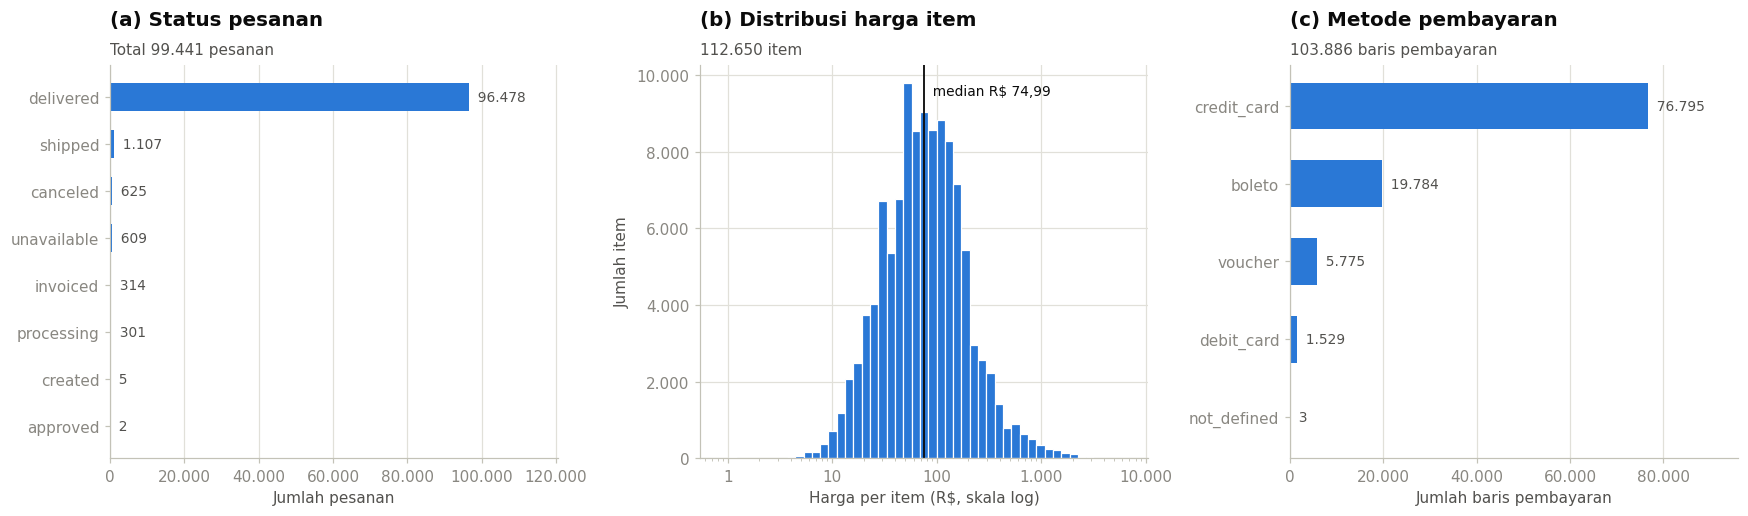

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# (a) Status pesanan
status_counts = orders['order_status'].value_counts().sort_values()
axes[0].barh(status_counts.index, status_counts.values, color=PALETTE[0], height=0.6)
for y, v in enumerate(status_counts.values):
    axes[0].text(v, y, f'  {fmt_id(v)}', va='center', fontsize=9, color=INK_SECONDARY)
axes[0].set_xlim(0, status_counts.max() * 1.25)
atur_sumbu_angka(axes[0], axis='x')
axes[0].grid(axis='y', visible=False)
axes[0].set_xlabel('Jumlah pesanan')
beri_judul(axes[0], '(a) Status pesanan', f'Total {fmt_id(len(orders))} pesanan')

# (b) Harga per item, sumbu X logaritmik
price = order_items['price']
bins = np.logspace(np.log10(price.min()), np.log10(price.max()), 50)
axes[1].hist(price, bins=bins, color=PALETTE[0], edgecolor='white', linewidth=0.8)
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: fmt_id(x)))
axes[1].xaxis.set_minor_formatter(NullFormatter())
axes[1].axvline(price.median(), color=INK_PRIMARY, lw=1.2)
axes[1].text(price.median(), axes[1].get_ylim()[1] * 0.95,
             f'  median R$ {fmt_id(price.median(), 2)}', fontsize=9, va='top')
atur_sumbu_angka(axes[1])
axes[1].set_xlabel('Harga per item (R$, skala log)')
axes[1].set_ylabel('Jumlah item')
beri_judul(axes[1], '(b) Distribusi harga item', f'{fmt_id(len(price))} item')

# (c) Metode pembayaran
pay_counts = payments['payment_type'].value_counts().sort_values()
axes[2].barh(pay_counts.index, pay_counts.values, color=PALETTE[0], height=0.6)
for y, v in enumerate(pay_counts.values):
    axes[2].text(v, y, f'  {fmt_id(v)}', va='center', fontsize=9, color=INK_SECONDARY)
axes[2].set_xlim(0, pay_counts.max() * 1.25)
atur_sumbu_angka(axes[2], axis='x')
axes[2].grid(axis='y', visible=False)
axes[2].set_xlabel('Jumlah baris pembayaran')
beri_judul(axes[2], '(c) Metode pembayaran', f'{fmt_id(len(payments))} baris pembayaran')

plt.tight_layout()
plt.show()

**Interpretasi.**
- **(a)** Status `delivered` mendominasi dengan 96.478 pesanan, sekitar 97% dari seluruh pesanan. Status `canceled` (625) dan `unavailable` (609) jumlahnya kecil. Keduanya tetap perlu dikeluarkan karena tidak mewakili penjualan yang benar-benar terjadi.
- **(b)** Pada skala log, sebaran harga membentuk lonceng dengan pusat di sekitar R$ 75. Pola ini mendekati distribusi log-normal: kebanyakan barang berharga puluhan hingga ratusan real, dan hanya sedikit yang melewati R$ 1.000.
- **(c)** Kartu kredit menjadi metode pembayaran utama (76.795 baris, sekitar 74%), disusul boleto (19.784 baris, sekitar 19%). Boleto adalah metode pembayaran berbasis slip tagihan yang umum di Brazil.

### 4.5 *Missing values*

In [13]:
missing_rows = []
for name, df in tables.items():
    n_missing = df.isna().sum()
    for col, n in n_missing[n_missing > 0].items():
        missing_rows.append({'tabel': name, 'kolom': col,
                             'jumlah_missing': int(n),
                             'persen': round(n / len(df) * 100, 2)})
missing_df = pd.DataFrame(missing_rows)
display(missing_df)

# Apakah tanggal terima yang kosong berkaitan dengan status pesanan?
missing_by_status = pd.crosstab(orders['order_status'],
                                orders['order_delivered_customer_date'].isna())
missing_by_status.columns = ['tanggal_terima_ada', 'tanggal_terima_kosong']
missing_by_status

,tabel,kolom,jumlah_missing,persen
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_category_name,610,1.85
4,products,product_name_lenght,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,products,product_weight_g,2,0.01
8,products,product_length_cm,2,0.01
9,products,product_height_cm,2,0.01


,tanggal_terima_ada,tanggal_terima_kosong
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


**Interpretasi.** *Missing values* hanya muncul di dua tabel, dan polanya masuk akal.
- **`orders`**: nilai kosong ada pada kolom tanggal proses (persetujuan, serah ke kurir, diterima pelanggan). Tabel silang memperlihatkan bahwa dari 2.965 tanggal terima yang kosong, 2.957 berasal dari pesanan yang memang belum atau tidak terkirim (`shipped`, `canceled`, `unavailable`, `invoiced`, dan lainnya). Hanya 8 pesanan berstatus `delivered` yang tanggal terimanya kosong. Kekosongan ini mencerminkan tahap proses pesanan, bukan kesalahan pencatatan.
- **`products`**: 610 produk (1,85%) tidak memiliki kategori. Produk tersebut tetap diikutkan dalam perhitungan dengan label kategori `unknown`.
- **Kolom acuan waktu**, `order_purchase_timestamp`, **tidak memiliki nilai kosong sama sekali**. Setiap pesanan dapat ditempatkan pada garis waktu.

### 4.6 Pemeriksaan duplikasi

In [14]:
dup_check = pd.DataFrame({
    'tabel': list(tables.keys()),
    'duplikat_seluruh_kolom': [int(df.duplicated().sum()) for df in tables.values()],
})
display(dup_check)

# customer_id dibuat per pesanan, sedangkan customer_unique_id mewakili orang yang sama
print(f"customer_id unik       : {customers['customer_id'].nunique():,}")
print(f"customer_unique_id unik: {customers['customer_unique_id'].nunique():,}")

# Satu pesanan bisa memiliki lebih dari satu baris pembayaran
pay_rows_per_order = payments.groupby('order_id').size()
print(f'\nPesanan dengan >1 baris pembayaran: {(pay_rows_per_order > 1).sum():,}')

,tabel,duplikat_seluruh_kolom
0,orders,0
1,order_items,0
2,products,0
3,category_translation,0
4,payments,0
5,customers,0


customer_id unik       : 99,441
customer_unique_id unik: 96,096

Pesanan dengan >1 baris pembayaran: 2,961


**Interpretasi.** Tidak ada baris duplikat penuh di keenam tabel. Ada dua catatan penting:
- `customer_id` berjumlah 99.441 (sama dengan jumlah pesanan), sedangkan `customer_unique_id` hanya 96.096. Ternyata `customer_id` dibuat baru untuk setiap pesanan. Untuk menghitung pelanggan unik, kolom yang tepat adalah `customer_unique_id`.
- Sebanyak 2.961 pesanan memiliki lebih dari satu baris pembayaran. Fakta ini menjadi alasan tabel `payments` harus diagregasi per pesanan sebelum digabung.

### 4.7 Analisis awal variabel waktu
Variabel waktu utama adalah `order_purchase_timestamp`. Di sini kolom tersebut dikonversi sementara untuk melihat rentang tanggal, sebaran pesanan per bulan, dan sebaran per jam. Konversi permanen dilakukan pada Bagian 5.1.

In [15]:
purchase_ts = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')

print('Timestamp pembelian kosong :', purchase_ts.isna().sum())
print('Pembelian pertama          :', purchase_ts.min())
print('Pembelian terakhir         :', purchase_ts.max())
print('Rentang waktu              :', (purchase_ts.max() - purchase_ts.min()).days, 'hari')

# Jumlah pesanan per bulan (semua status), termasuk bulan tanpa transaksi
monthly_all_status = purchase_ts.dt.to_period('M').value_counts().sort_index()
full_months = pd.period_range(monthly_all_status.index.min(),
                              monthly_all_status.index.max(), freq='M')
monthly_all_status = monthly_all_status.reindex(full_months, fill_value=0)
monthly_all_status.to_frame('jumlah_pesanan').T

Timestamp pembelian kosong : 0
Pembelian pertama          : 2016-09-04 21:15:19
Pembelian terakhir         : 2018-10-17 17:30:18
Rentang waktu              : 772 hari


,2016-09,2016-10,2016-11,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
jumlah_pesanan,4,324,0,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


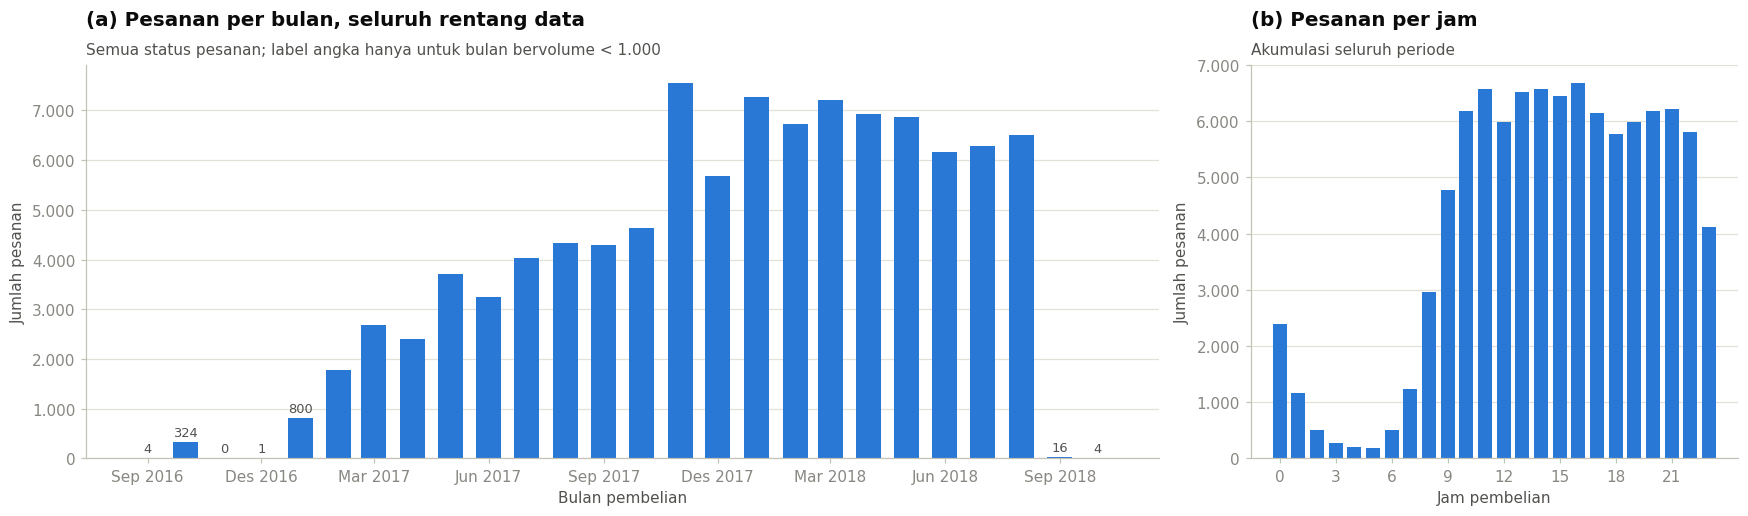

Pesanan pukul 10.00-22.59 : 81.5%
Pesanan pukul 00.00-06.59 : 5.3%
Jam tersibuk: pukul 16.00 (6,675 pesanan); jam tersepi: pukul 05.00 (188 pesanan)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})

# (a) Pesanan per bulan untuk seluruh rentang data
month_dates = monthly_all_status.index.to_timestamp()
axes[0].bar(month_dates, monthly_all_status.values, width=20, color=PALETTE[0])
for x, v in zip(month_dates, monthly_all_status.values):
    if v < 1000:  # beri label hanya pada bulan yang volumenya sangat kecil
        axes[0].text(x, v + 120, fmt_id(v), ha='center', fontsize=8.5, color=INK_SECONDARY)
atur_sumbu_bulan(axes[0], month_dates, interval=3)
atur_sumbu_angka(axes[0])
axes[0].grid(axis='x', visible=False)
axes[0].set_xlabel('Bulan pembelian')
axes[0].set_ylabel('Jumlah pesanan')
beri_judul(axes[0], '(a) Pesanan per bulan, seluruh rentang data',
           'Semua status pesanan; label angka hanya untuk bulan bervolume < 1.000')

# (b) Pesanan per jam dalam sehari
hourly = purchase_ts.dt.hour.value_counts().sort_index()
axes[1].bar(hourly.index, hourly.values, color=PALETTE[0], width=0.75)
axes[1].set_xticks(range(0, 24, 3))
atur_sumbu_angka(axes[1])
axes[1].grid(axis='x', visible=False)
axes[1].set_xlabel('Jam pembelian')
axes[1].set_ylabel('Jumlah pesanan')
beri_judul(axes[1], '(b) Pesanan per jam', 'Akumulasi seluruh periode')

plt.tight_layout()
plt.show()

print(f'Pesanan pukul 10.00-22.59 : {hourly.loc[10:22].sum() / hourly.sum():.1%}')
print(f'Pesanan pukul 00.00-06.59 : {hourly.loc[0:6].sum() / hourly.sum():.1%}')
print(f'Jam tersibuk: pukul {hourly.idxmax():02d}.00 ({hourly.max():,} pesanan); '
      f'jam tersepi: pukul {hourly.idxmin():02d}.00 ({hourly.min():,} pesanan)')

**Interpretasi.**
- Data mencakup pembelian dari **4 September 2016** sampai **17 Oktober 2018** (772 hari). Namun, volumenya tidak merata di sepanjang rentang tersebut.
- Akhir 2016 nyaris kosong: September 2016 hanya berisi 4 pesanan, Oktober 2016 sebanyak 324, November 2016 tidak ada sama sekali, dan Desember 2016 hanya 1. Pola serupa muncul di ujung akhir, yaitu September 2018 dengan 16 pesanan dan Oktober 2018 dengan 4 pesanan. Bulan-bulan ini lebih mungkin mencerminkan batas pengumpulan data daripada kondisi pasar yang sebenarnya.
- Dari Januari 2017 sampai Agustus 2018 volume bulanan konsisten di level ratusan hingga ribuan pesanan. Rentang ini menjadi kandidat periode analisis dan ditetapkan secara formal di Bagian 5.5.
- Menurut jam pembelian, sekitar 82% pesanan terjadi pada pukul 10.00 sampai 22.59. Rentang pukul 00.00 sampai 06.59 hanya menyumbang sekitar 5%, dengan titik tersepi pada pukul 05.00. Aktivitas belanja jelas mengikuti jam aktif konsumen.

## 5. Data Preprocessing

Tahapan *preprocessing*:
1. Konversi kolom tanggal ke tipe *datetime* dan optimasi memori.
2. Pemeriksaan transaksi tidak valid.
3. Penyaringan pesanan valid.
4. Penggabungan tabel dengan verifikasi agar tidak terjadi duplikasi.
5. Penentuan rentang waktu analisis berdasarkan data, lalu pengurutan kronologis.
6. Agregasi menjadi data *time series* harian dan bulanan.

### 5.1 Konversi tanggal ke *datetime*

In [17]:
DATE_COLS_ORDERS = [
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date',
]
missing_before = orders[DATE_COLS_ORDERS].isna().sum()

# errors='coerce' mengubah teks yang tidak bisa dibaca menjadi NaT
for col in DATE_COLS_ORDERS:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'],
                                                    errors='coerce')

conversion_check = pd.DataFrame({
    'tipe_baru': orders[DATE_COLS_ORDERS].dtypes.astype(str),
    'kosong_sebelum': missing_before,
    'NaT_sesudah': orders[DATE_COLS_ORDERS].isna().sum(),
})
conversion_check

,tipe_baru,kosong_sebelum,NaT_sesudah
order_purchase_timestamp,datetime64[us],0,0
order_approved_at,datetime64[us],160,160
order_delivered_carrier_date,datetime64[us],1783,1783
order_delivered_customer_date,datetime64[us],2965,2965
order_estimated_delivery_date,datetime64[us],0,0


**Interpretasi.** Kelima kolom tanggal berhasil diubah menjadi *datetime*. Jumlah NaT setelah konversi sama persis dengan jumlah nilai kosong sebelumnya, jadi tidak ada teks tanggal dengan format rusak. NaT yang tersisa adalah nilai yang sejak awal memang kosong (lihat Bagian 4.5). Presisi yang tampil (`datetime64[ns]` atau `datetime64[us]`) bergantung pada versi pandas dan tidak memengaruhi analisis.

Sel berikutnya mengubah beberapa kolom teks yang nilainya berulang (misalnya status pesanan dan nama kota) menjadi tipe `category` untuk menghemat memori.

In [18]:
# Kolom teks yang nilainya berulang diubah ke tipe category agar hemat memori
mem_before = sum(df.memory_usage(deep=True).sum() for df in tables.values()) / 1024**2

orders['order_status'] = orders['order_status'].astype('category')
payments['payment_type'] = payments['payment_type'].astype('category')
customers['customer_state'] = customers['customer_state'].astype('category')
customers['customer_city'] = customers['customer_city'].astype('category')

mem_after = sum(df.memory_usage(deep=True).sum() for df in tables.values()) / 1024**2
print(f'Memori seluruh tabel: {mem_before:.1f} MB -> {mem_after:.1f} MB')

Memori seluruh tabel: 52.2 MB -> 46.7 MB


### 5.2 Pemeriksaan transaksi tidak valid

In [19]:
INVALID_STATUS = ['canceled', 'unavailable']

checks = {
    'Timestamp pembelian kosong (NaT)':
        orders['order_purchase_timestamp'].isna().sum(),
    'Status canceled / unavailable':
        orders['order_status'].isin(INVALID_STATUS).sum(),
    'Pesanan tanpa item di order_items':
        (~orders['order_id'].isin(order_items['order_id'])).sum(),
    'Item dengan price <= 0':
        (order_items['price'] <= 0).sum(),
    'Item dengan freight_value < 0':
        (order_items['freight_value'] < 0).sum(),
    'Disetujui sebelum dibeli (approved < purchase)':
        (orders['order_approved_at'] < orders['order_purchase_timestamp']).sum(),
    'Diterima pelanggan sebelum dibeli':
        (orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']).sum(),
    'Diserahkan ke kurir sebelum dibeli':
        (orders['order_delivered_carrier_date'] < orders['order_purchase_timestamp']).sum(),
    'Status delivered tetapi tanggal terima kosong':
        ((orders['order_status'] == 'delivered')
         & orders['order_delivered_customer_date'].isna()).sum(),
}
invalid_check = pd.DataFrame({'pemeriksaan': list(checks.keys()),
                              'jumlah': [int(v) for v in checks.values()]})
invalid_check

,pemeriksaan,jumlah
0,Timestamp pembelian kosong (NaT),0
1,Status canceled / unavailable,1234
2,Pesanan tanpa item di order_items,775
3,Item dengan price <= 0,0
4,Item dengan freight_value < 0,0
5,Disetujui sebelum dibeli (approved < purchase),0
6,Diterima pelanggan sebelum dibeli,0
7,Diserahkan ke kurir sebelum dibeli,166
8,Status delivered tetapi tanggal terima kosong,8


**Interpretasi dan keputusan penanganan**

| Temuan | Jumlah | Keputusan |
|---|---|---|
| Status `canceled` / `unavailable` | 1.234 | **Dikeluarkan.** Pesanan batal atau barang tidak tersedia bukan penjualan yang terealisasi. |
| Pesanan tanpa item | 775 | **Dikeluarkan.** Tanpa item tidak ada nilai `price` dan kategori produk. |
| *Timestamp* pembelian kosong | 0 | Tidak ada yang perlu dihapus. |
| `price` ≤ 0 atau ongkir negatif | 0 | Tidak ada nilai uang yang tidak wajar. |
| Diserahkan ke kurir sebelum tanggal beli | 166 | **Dibiarkan.** Anomali ini ada di kolom proses logistik, bukan pada waktu pembelian atau nilai penjualan yang dianalisis. |
| `delivered` tanpa tanggal terima | 8 | **Dibiarkan**, dengan alasan yang sama. |

Dua kelompok yang dikeluarkan sebagian beririsan, sebab ada pesanan batal yang juga tidak memiliki item. Total pesanan yang dikeluarkan dihitung langsung pada sel berikutnya.

### 5.3 Penyaringan pesanan valid
Pesanan dianggap **valid** jika memenuhi tiga syarat: memiliki *timestamp* pembelian, statusnya bukan `canceled` atau `unavailable`, dan memiliki minimal satu item. Status lain (`delivered`, `shipped`, `invoiced`, `processing`, `approved`, `created`) tetap dipertahankan karena merupakan transaksi yang sudah terjadi, hanya tahap pemrosesannya yang berbeda. Jika hanya pesanan `delivered` yang dipakai, bulan-bulan terakhir akan tampak lebih rendah dari kenyataan karena sebagian pesanannya belum sampai ketika data diambil.

In [20]:
valid_mask = (
    orders['order_purchase_timestamp'].notna()
    & ~orders['order_status'].isin(INVALID_STATUS)
    & orders['order_id'].isin(order_items['order_id'])
)
orders_valid = orders.loc[valid_mask].copy()

print(f'Pesanan awal        : {len(orders):,}')
print(f'Pesanan dikeluarkan : {(~valid_mask).sum():,}')
print(f'Pesanan valid       : {len(orders_valid):,}')
print('\nKomposisi status pesanan valid:')
status_valid = orders_valid['order_status'].value_counts()
print(status_valid[status_valid > 0].to_string())

Pesanan awal        : 99,441
Pesanan dikeluarkan : 1,242
Pesanan valid       : 98,199

Komposisi status pesanan valid:
order_status
delivered     96478
shipped        1106
invoiced        312
processing      301
approved          2


### 5.4 Penggabungan tabel (*merge*)
Penggabungan dilakukan bertahap. Pada setiap `merge`, parameter `validate` dipakai agar pandas langsung memunculkan *error* bila relasi tidak sesuai dugaan, misalnya kunci yang seharusnya unik ternyata ganda. Setelah itu jumlah baris dicek ulang dengan `assert`.

1. `products` + `category_translation` (*many-to-one*): menambahkan nama kategori berbahasa Inggris.
2. `order_items` + `orders_valid` (*many-to-one*, *inner join*): setiap item mendapat waktu pembelian, sekaligus menyaring item milik pesanan tidak valid.
3. Hasil langkah 2 + kategori produk (*many-to-one*).
4. Tabel tingkat pesanan: `orders_valid` + `customers` (*one-to-one*) + ringkasan item per pesanan (*one-to-one*).

In [21]:
# Langkah 1: products + terjemahan kategori
products_cat = products[['product_id', 'product_category_name']].merge(
    category_translation, on='product_category_name', how='left', validate='many_to_one')

# Kategori tanpa terjemahan memakai nama Portugis; produk tanpa kategori diberi label 'unknown'
products_cat['category'] = (products_cat['product_category_name_english']
                            .fillna(products_cat['product_category_name'])
                            .fillna('unknown'))

# Langkah 2: item + waktu pembelian (inner join = hanya item milik pesanan valid)
sales_items = order_items.merge(
    orders_valid[['order_id', 'order_purchase_timestamp']],
    on='order_id', how='inner', validate='many_to_one')

# Langkah 3: item + kategori produk
sales_items = sales_items.merge(
    products_cat[['product_id', 'category']],
    on='product_id', how='left', validate='many_to_one')

# Verifikasi: jumlah baris harus sama dengan jumlah item milik pesanan valid
expected_rows = order_items['order_id'].isin(orders_valid['order_id']).sum()
assert len(sales_items) == expected_rows, 'Jumlah baris berubah, ada duplikasi akibat merge!'
assert sales_items['category'].notna().all()

print(f'Baris sales_items              : {len(sales_items):,}')
print(f'Jumlah item milik pesanan valid: {expected_rows:,}')
print(f"Kategori unik                  : {sales_items['category'].nunique()}")
print(f"Item berkategori 'unknown'     : {(sales_items['category'] == 'unknown').sum():,}")
sales_items.head(3)

Baris sales_items              : 112,101
Jumlah item milik pesanan valid: 112,101
Kategori unik                  : 74
Item berkategori 'unknown'     : 1,589


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,2017-09-13 08:59:02,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,2017-04-26 10:53:06,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,2018-01-14 14:33:31,furniture_decor


In [22]:
# Langkah 4: tabel tingkat pesanan (satu baris = satu pesanan)
per_order = sales_items.groupby('order_id').agg(
    gmv_order=('price', 'sum'),            # nilai barang per pesanan
    ongkir_order=('freight_value', 'sum'),
    jumlah_item=('order_item_id', 'count'),
).reset_index()

orders_clean = (
    orders_valid[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']]
    .merge(customers[['customer_id', 'customer_unique_id', 'customer_state']],
           on='customer_id', how='left', validate='one_to_one')
    .merge(per_order, on='order_id', how='left', validate='one_to_one')
)

assert len(orders_clean) == len(orders_valid)
assert orders_clean['order_id'].is_unique
assert np.isclose(orders_clean['gmv_order'].sum(), sales_items['price'].sum())

print(f'Baris orders_clean: {len(orders_clean):,} (satu baris per pesanan valid)')
orders_clean.head(3)

Baris orders_clean: 98,199 (satu baris per pesanan valid)


,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id,customer_state,gmv_order,ongkir_order,jumlah_item
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,SP,29.99,8.72,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,BA,118.70,22.76,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,GO,159.90,19.22,1


**Mengapa `payments` tidak langsung digabung dengan `order_items`?** Kedua tabel sama-sama memiliki banyak baris untuk satu `order_id`. Penggabungan langsung menghasilkan relasi *many-to-many*: setiap item dipasangkan dengan setiap baris pembayaran pada pesanan yang sama. Sel berikut menunjukkan dampaknya.

In [23]:
# Contoh merge yang SALAH: order_items langsung digabung dengan payments
naive_merge = order_items.merge(payments, on='order_id', how='inner')
print(f"Baris order_items             : {len(order_items):,}")
print(f"Baris setelah merge langsung  : {len(naive_merge):,}")
print(f"Total price yang benar        : R$ {order_items['price'].sum():,.2f}")
print(f"Total price setelah merge     : R$ {naive_merge['price'].sum():,.2f}")
inflation = naive_merge['price'].sum() / order_items['price'].sum() - 1
print(f'Kelebihan hitung              : {inflation:.2%}')

# Cara yang BENAR: agregasi pembayaran per pesanan dulu, baru digabung (one-to-one)
payment_per_order = payments.groupby('order_id', as_index=False)['payment_value'].sum()
pay_check = per_order.merge(payment_per_order, on='order_id', how='inner', validate='one_to_one')
pay_check['selisih'] = pay_check['payment_value'] - (pay_check['gmv_order'] + pay_check['ongkir_order'])
share_match = (pay_check['selisih'].abs() <= 1).mean()

print(f'\nPesanan valid yang memiliki data pembayaran: {len(pay_check):,}')
print(f'Pembayaran = price + ongkir (selisih <= R$1): {share_match:.2%} pesanan')

Baris order_items             : 112,650
Baris setelah merge langsung  : 117,601
Total price yang benar        : R$ 13,591,643.70
Total price setelah merge     : R$ 14,209,115.34
Kelebihan hitung              : 4.54%

Pesanan valid yang memiliki data pembayaran: 98,198
Pembayaran = price + ongkir (selisih <= R$1): 99.75% pesanan


**Interpretasi.**
- **Semua tahap *merge* lolos validasi.** `sales_items` berisi 112.101 baris, persis sama dengan jumlah item milik pesanan valid. `orders_clean` berisi 98.199 baris dengan `order_id` yang unik. Tidak ada baris yang berlipat akibat penggabungan.
- **Ada 74 label kategori**, terdiri dari 71 kategori berbahasa Inggris, 2 kategori bernama Portugis, dan `unknown` untuk 1.589 item yang produknya tidak berkategori.
- **Contoh *merge* yang salah membuktikan risikonya.** Menggabungkan `order_items` langsung dengan `payments` menaikkan jumlah baris dari 112.650 menjadi 117.601 dan membuat total `price` membengkak 4,54% (dari sekitar R$ 13,59 juta menjadi R$ 14,21 juta). Kesalahan seperti ini berbahaya karena kodenya tetap berjalan tanpa *error*.
- **Validasi silang dengan pembayaran.** Setelah pembayaran diagregasi per pesanan, 99,75% pesanan memiliki nilai pembayaran yang sama dengan `price` + ongkir (selisih paling banyak R$ 1). Hasil ini menguatkan bahwa kolom `price` di `order_items` dapat diandalkan sebagai dasar perhitungan GMV.

### 5.5 Penentuan rentang waktu analisis dan pengurutan kronologis
Grafik pada Bagian 4.7 menunjukkan bahwa volume pesanan tidak merata di awal dan di akhir rentang data. Agar penentuan periode tidak berdasarkan kira-kira, dipakai aturan sederhana berikut:

1. Hitung jumlah pesanan valid per bulan untuk seluruh rentang data (bulan tanpa transaksi bernilai 0).
2. Sebuah bulan dianggap **aktif** jika jumlah pesanannya minimal **10% dari median** jumlah pesanan bulanan.
3. Periode analisis adalah **rangkaian bulan aktif berturut-turut yang paling panjang**.

Aturan ini membuang bulan yang datanya jelas belum lengkap tanpa menyentuh bulan-bulan dengan aktivitas normal.

In [24]:
# Jumlah pesanan valid per bulan; resample otomatis mengisi bulan kosong dengan 0
monthly_valid_all = orders_clean.set_index('order_purchase_timestamp').resample('MS').size()

THRESHOLD_RATIO = 0.10
threshold = THRESHOLD_RATIO * monthly_valid_all.median()
is_active = monthly_valid_all >= threshold

# Kumpulkan semua rangkaian bulan aktif yang berurutan
runs, run_start, prev_month = [], None, None
for month, active in is_active.items():
    if active and run_start is None:
        run_start = month
    if not active and run_start is not None:
        runs.append((run_start, prev_month))
        run_start = None
    prev_month = month
if run_start is not None:
    runs.append((run_start, prev_month))

# Pilih rangkaian terpanjang
start_month, end_month = max(runs, key=lambda r: len(monthly_valid_all.loc[r[0]:r[1]]))
end_exclusive = end_month + pd.DateOffset(months=1)

print(f'Median pesanan valid per bulan : {monthly_valid_all.median():,.0f}')
print(f'Ambang bulan aktif (10%)       : {threshold:,.0f} pesanan')
print(f'Rangkaian bulan aktif          : {[(format_bulan(a), format_bulan(b)) for a, b in runs]}')
print(f'Periode analisis               : {format_bulan(start_month)} s.d. {format_bulan(end_month)}')

window_table = pd.DataFrame({
    'jumlah_pesanan_valid': monthly_valid_all.values,
    'status': np.where(monthly_valid_all.index.to_series().between(start_month, end_month),
                       'Dipakai', 'Dikeluarkan'),
}, index=[format_bulan(m) for m in monthly_valid_all.index])
window_table.T

Median pesanan valid per bulan : 4,227
Ambang bulan aktif (10%)       : 423 pesanan
Rangkaian bulan aktif          : [('Jan 2017', 'Agu 2018')]
Periode analisis               : Jan 2017 s.d. Agu 2018


,Sep 2016,Okt 2016,Nov 2016,Des 2016,Jan 2017,Feb 2017,Mar 2017,Apr 2017,Mei 2017,Jun 2017,Jul 2017,Agu 2017,Sep 2017,Okt 2017,Nov 2017,Des 2017,Jan 2018,Feb 2018,Mar 2018,Apr 2018,Mei 2018,Jun 2018,Jul 2018,Agu 2018,Sep 2018
jumlah_pesanan_valid,2,290,0,1,787,1718,2617,2377,3640,3205,3946,4272,4227,4547,7421,5618,7187,6624,7168,6919,6833,6145,6233,6421,1
status,Dikeluarkan,Dikeluarkan,Dikeluarkan,Dikeluarkan,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dipakai,Dikeluarkan


In [25]:
# Saring data ke periode analisis lalu urutkan secara kronologis
in_window = orders_clean['order_purchase_timestamp'].between(start_month, end_exclusive,
                                                            inclusive='left')
orders_ts = (orders_clean.loc[in_window]
             .sort_values('order_purchase_timestamp')
             .reset_index(drop=True))

in_window_items = sales_items['order_purchase_timestamp'].between(start_month, end_exclusive,
                                                                 inclusive='left')
sales_ts = (sales_items.loc[in_window_items]
            .sort_values('order_purchase_timestamp')
            .reset_index(drop=True))

print(f'Pesanan di periode analisis : {len(orders_ts):,} '
      f'({len(orders_ts) / len(orders_clean):.2%} dari pesanan valid)')
print(f'Pesanan di luar periode     : {len(orders_clean) - len(orders_ts):,}')
print(f'Item di periode analisis    : {len(sales_ts):,}')
print(f"Transaksi pertama           : {orders_ts['order_purchase_timestamp'].min()}")
print(f"Transaksi terakhir          : {orders_ts['order_purchase_timestamp'].max()}")
print('Urutan kronologis           :',
      orders_ts['order_purchase_timestamp'].is_monotonic_increasing)

Pesanan di periode analisis : 97,905 (99.70% dari pesanan valid)
Pesanan di luar periode     : 294
Item di periode analisis    : 111,752
Transaksi pertama           : 2017-01-05 11:56:06
Transaksi terakhir          : 2018-08-29 15:00:37
Urutan kronologis           : True


**Interpretasi.**
- Median pesanan valid per bulan adalah 4.227, sehingga ambang bulan aktif sebesar 423 pesanan. Hanya terbentuk satu rangkaian bulan aktif berturut-turut, yaitu **Januari 2017 sampai Agustus 2018 (20 bulan)**.
- Bulan yang dikeluarkan adalah September sampai Desember 2016 serta September 2018, dengan volume pesanan valid antara 0 dan 290 per bulan. Oktober 2018 tidak muncul di tabel karena tidak ada satu pun pesanan valid di bulan itu.
- Periode terpilih memuat **97.905 pesanan atau 99,70% dari seluruh pesanan valid**. Hanya 294 pesanan yang tidak ikut dianalisis, jadi pemotongan periode hampir tidak mengurangi informasi.
- Transaksi pertama pada periode ini terjadi tanggal 5 Januari 2017 dan transaksi terakhir tanggal 29 Agustus 2018. Data juga sudah terurut kronologis, syarat penting sebelum menghitung *moving average*.

### 5.6 Agregasi data *time series*
Tiga tabel *time series* disiapkan:
- `daily`: per hari, berisi jumlah pesanan, GMV, dan jumlah item terjual.
- `monthly`: per bulan, berisi kolom yang sama ditambah jumlah pelanggan unik dan nilai rata-rata per pesanan.
- `monthly_category`: GMV per bulan untuk setiap kategori produk.

Jumlah pesanan dihitung dari tabel tingkat pesanan (`orders_ts`) sehingga satu pesanan tidak mungkin terhitung dua kali. GMV per kategori dihitung dari tabel tingkat item (`sales_ts`) karena satu pesanan bisa berisi produk dari kategori berbeda.

In [26]:
# ---------- Agregasi harian ----------
daily = (orders_ts
         .groupby(orders_ts['order_purchase_timestamp'].dt.floor('D'))
         .agg(jumlah_order=('order_id', 'count'),
              gmv=('gmv_order', 'sum'),
              item_terjual=('jumlah_item', 'sum')))
daily.index.name = 'tanggal'
n_days_before = len(daily)
daily = daily.asfreq('D', fill_value=0)   # pastikan tidak ada tanggal yang terlewat

# ---------- Agregasi bulanan ----------
monthly = (orders_ts
           .groupby(pd.Grouper(key='order_purchase_timestamp', freq='MS'))
           .agg(jumlah_order=('order_id', 'count'),
                gmv=('gmv_order', 'sum'),
                item_terjual=('jumlah_item', 'sum'),
                pelanggan_unik=('customer_unique_id', 'nunique')))
monthly.index.name = 'bulan'
monthly['nilai_rata2_order'] = monthly['gmv'] / monthly['jumlah_order']

# ---------- GMV bulanan per kategori ----------
monthly_category = (sales_ts
                    .groupby([pd.Grouper(key='order_purchase_timestamp', freq='MS'), 'category'])
                    ['price'].sum()
                    .unstack(fill_value=0))
monthly_category.index.name = 'bulan'
category_totals = monthly_category.sum().sort_values(ascending=False)

print(f'Hari dengan transaksi        : {n_days_before}')
print(f'Hari kalender dalam rentang  : {len(daily)} ({daily.index.min().date()} s.d. {daily.index.max().date()})')
print(f"Hari tanpa transaksi sama sekali: {(daily['jumlah_order'] == 0).sum()}")

Hari dengan transaksi        : 602
Hari kalender dalam rentang  : 602 (2017-01-05 s.d. 2018-08-29)
Hari tanpa transaksi sama sekali: 0


In [27]:
# Verifikasi konsistensi: semua agregat harus kembali ke total yang sama
total_gmv = sales_ts['price'].sum()
assert np.isclose(daily['gmv'].sum(), total_gmv)
assert np.isclose(monthly['gmv'].sum(), total_gmv)
assert np.isclose(monthly_category.to_numpy().sum(), total_gmv)
assert daily['jumlah_order'].sum() == monthly['jumlah_order'].sum() == len(orders_ts)
assert daily['item_terjual'].sum() == monthly['item_terjual'].sum() == len(sales_ts)
print('Semua pemeriksaan konsistensi agregasi lolos.\n')

summary = pd.Series({
    'Periode': f'{format_tanggal(daily.index.min())} s.d. {format_tanggal(daily.index.max())}',
    'Jumlah hari': f'{len(daily):,}',
    'Jumlah bulan': f'{len(monthly)}',
    'Total pesanan valid': f'{len(orders_ts):,}',
    'Total item terjual': f'{len(sales_ts):,}',
    'Total GMV (R$)': f'{total_gmv:,.2f}',
    'Jumlah kategori': f'{monthly_category.shape[1]}',
})
summary.to_frame('nilai')

Semua pemeriksaan konsistensi agregasi lolos.



,nilai
Periode,5 Jan 2017 s.d. 29 Agu 2018
Jumlah hari,602
Jumlah bulan,20
Total pesanan valid,"97,905"
Total item terjual,"111,752"
Total GMV (R$),"13,449,529.68"
Jumlah kategori,74


In [28]:
print('Tabel bulanan:')
monthly_display = monthly.copy()
monthly_display.index = [format_bulan(m) for m in monthly.index]
display(monthly_display.style.format({
    'jumlah_order': '{:,.0f}', 'gmv': 'R$ {:,.0f}', 'item_terjual': '{:,.0f}',
    'pelanggan_unik': '{:,.0f}', 'nilai_rata2_order': 'R$ {:,.2f}'}))

print('10 kategori dengan GMV terbesar:')
top10 = category_totals.head(10).to_frame('gmv')
top10['porsi_%'] = (top10['gmv'] / category_totals.sum() * 100).round(2)
top10['label'] = [label_kategori(c) for c in top10.index]
display(top10.style.format({'gmv': 'R$ {:,.0f}', 'porsi_%': '{:.2f}'}))

Tabel bulanan:


,jumlah_order,gmv,item_terjual,pelanggan_unik,nilai_rata2_order
Jan 2017,787,"R$ 120,098",953,753,R$ 152.60
Feb 2017,"1,718","R$ 244,959","1,936","1,693",R$ 142.58
Mar 2017,"2,617","R$ 368,341","2,975","2,577",R$ 140.75
Apr 2017,"2,377","R$ 353,843","2,660","2,345",R$ 148.86
Mei 2017,"3,640","R$ 503,159","4,106","3,569",R$ 138.23
Jun 2017,"3,205","R$ 429,917","3,571","3,142",R$ 134.14
Jul 2017,"3,946","R$ 492,287","4,493","3,872",R$ 124.76
Agu 2017,"4,272","R$ 568,246","4,882","4,191",R$ 133.02
Sep 2017,"4,227","R$ 621,416","4,815","4,154",R$ 147.01
Okt 2017,"4,547","R$ 660,180","5,300","4,481",R$ 145.19


10 kategori dengan GMV terbesar:


,gmv,porsi_%,label
category,,,
health_beauty,"R$ 1,251,146",9.30,Kesehatan & Kecantikan
watches_gifts,"R$ 1,194,825",8.88,Jam Tangan & Hadiah
bed_bath_table,"R$ 1,035,485",7.70,"Kasur, Mandi & Meja"
sports_leisure,"R$ 977,729",7.27,Olahraga & Rekreasi
computers_accessories,"R$ 902,923",6.71,Komputer & Aksesori
furniture_decor,"R$ 721,584",5.37,Furnitur & Dekorasi
housewares,"R$ 625,539",4.65,Peralatan Rumah Tangga
cool_stuff,"R$ 619,724",4.61,Barang Unik
auto,"R$ 585,177",4.35,Otomotif


## 6. Time Series Visualization
Empat visualisasi wajib dibuat dari tabel agregasi pada Bagian 5.6:

| No | Jenis plot | Variabel | Granularitas |
|---|---|---|---|
| 6.1 | *Line plot* | Jumlah pesanan | Bulanan |
| 6.2 | *Stacked area plot* | GMV per kategori (5 teratas + lainnya) | Bulanan |
| 6.3 | *Multiple time series* | GMV 3 kategori teratas | Bulanan |
| 6.4 | *Calendar heatmap* | Rata-rata pesanan per hari | Hari dalam seminggu × bulan, ditambah kalender harian |

Warna setiap kategori dikunci sejak grafik area sehingga kategori yang sama selalu tampil dengan warna yang sama di grafik berikutnya.

### 6.1 *Line Plot*: perkembangan jumlah pesanan bulanan

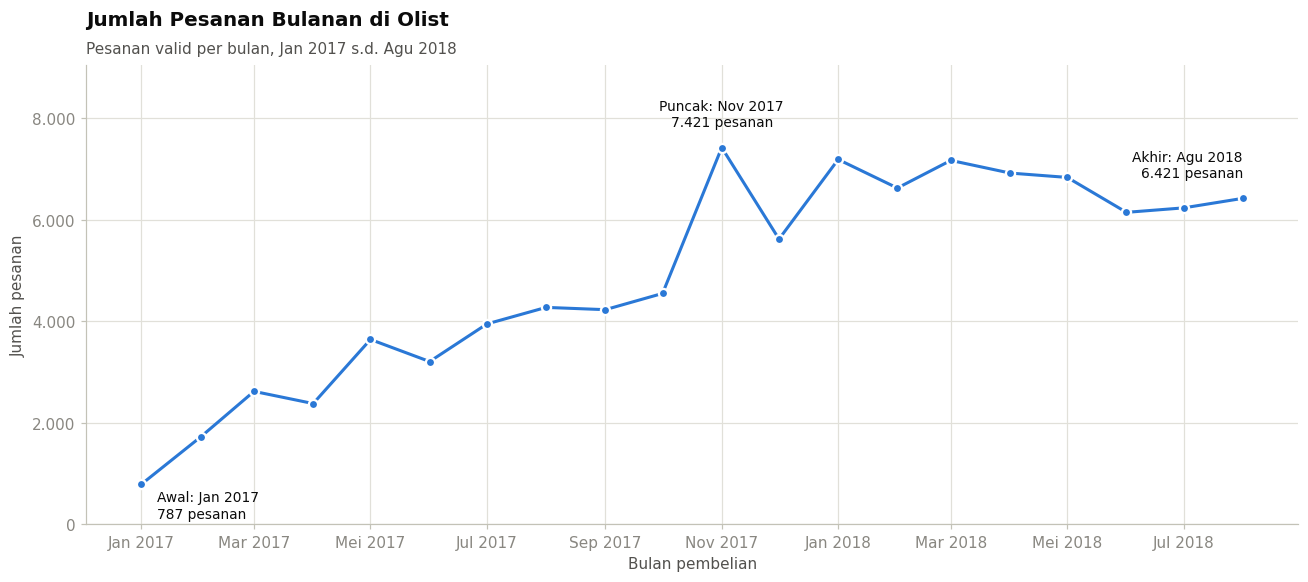

In [29]:
fig, ax = plt.subplots(figsize=(12, 5.4))
ax.plot(monthly.index, monthly['jumlah_order'], color=PALETTE[0], lw=2,
        marker='o', ms=6, markeredgecolor='white', markeredgewidth=1.5)

# Label selektif: titik awal, titik puncak, dan titik akhir
peak_month = monthly['jumlah_order'].idxmax()
# (nama label, posisi teks relatif terhadap titik dalam satuan point, perataan horizontal, vertikal)
highlights = {monthly.index[0]: ('Awal', (10, -4), 'left', 'top'),
              peak_month: ('Puncak', (0, 12), 'center', 'bottom'),
              monthly.index[-1]: ('Akhir', (0, 12), 'right', 'bottom')}
for month, (name, offset, ha, va) in highlights.items():
    value = monthly.loc[month, 'jumlah_order']
    ax.annotate(f'{name}: {format_bulan(month)}\n{fmt_id(value)} pesanan',
                xy=(mdates.date2num(month), value), xytext=offset,
                textcoords='offset points', ha=ha, va=va, fontsize=9)

ax.set_ylim(0, monthly['jumlah_order'].max() * 1.22)
atur_sumbu_bulan(ax, monthly.index, interval=2)
atur_sumbu_angka(ax)
ax.set_xlabel('Bulan pembelian')
ax.set_ylabel('Jumlah pesanan')
beri_judul(ax, 'Jumlah Pesanan Bulanan di Olist',
           f'Pesanan valid per bulan, {format_bulan(start_month)} s.d. {format_bulan(end_month)}')
plt.tight_layout()
plt.show()

In [30]:
# Angka pendukung interpretasi line plot
first, last = monthly.index[0], monthly.index[-1]
mom = monthly['jumlah_order'].pct_change() * 100

print(f"Pesanan {format_bulan(first)}: {monthly.loc[first, 'jumlah_order']:,}")
print(f"Pesanan puncak {format_bulan(peak_month)}: {monthly.loc[peak_month, 'jumlah_order']:,} "
      f"({mom[peak_month]:+.1f}% dibanding bulan sebelumnya)")
print(f"Pesanan {format_bulan(last)}: {monthly.loc[last, 'jumlah_order']:,}")
print(f'Kenaikan bulanan terbesar : {format_bulan(mom.idxmax())} ({mom.max():+.1f}%)')
print(f'Penurunan bulanan terbesar: {format_bulan(mom.idxmin())} ({mom.min():+.1f}%)')

print('\nRingkasan per tahun (pesanan per bulan):')
per_year = monthly.groupby(monthly.index.year)['jumlah_order'].agg(['count', 'sum', 'mean', 'min', 'max'])
per_year.columns = ['jumlah_bulan', 'total', 'rata2_per_bulan', 'minimum', 'maksimum']
per_year.round(0)

Pesanan Jan 2017: 787
Pesanan puncak Nov 2017: 7,421 (+63.2% dibanding bulan sebelumnya)
Pesanan Agu 2018: 6,421
Kenaikan bulanan terbesar : Feb 2017 (+118.3%)
Penurunan bulanan terbesar: Des 2017 (-24.3%)

Ringkasan per tahun (pesanan per bulan):


,jumlah_bulan,total,rata2_per_bulan,minimum,maksimum
bulan,,,,,
2017,12,44375,3698.0,787,7421
2018,8,53530,6691.0,6145,7187


**Interpretasi (menjawab pertanyaan 1).**
- **Tren naik kuat sepanjang 2017.** Jumlah pesanan tumbuh dari 787 pada Januari 2017 menjadi 4.547 pada Oktober 2017. Kenaikan bulanan terbesar terjadi pada Februari 2017 (+118,3%). Angka Januari 2017 terlihat kecil antara lain karena data bulan itu baru dimulai pada tanggal 5.
- **Puncak pada November 2017** dengan 7.421 pesanan, melonjak 63,2% dibanding Oktober. Lonjakan ini bertepatan dengan Black Friday (24 November 2017) dan dibahas lebih rinci di Bagian 6.4.
- **Koreksi pada Desember 2017.** Pesanan turun 24,3%, penurunan bulanan terbesar selama periode pengamatan. Setelah momen promosi berlalu, aktivitas kembali ke level yang lebih wajar.
- **Mendatar (*plateau*) sepanjang 2018.** Pesanan bulanan Januari sampai Agustus 2018 bergerak dalam rentang sempit, yaitu 6.145 sampai 7.187. Rata-rata per bulannya (6.691) sekitar 1,8 kali rata-rata 2017 (3.698). Namun, garisnya tidak lagi menanjak seperti pada tahun sebelumnya.

### 6.2 *Area Plot*: volume GMV bulanan per kategori
*Stacked area* dipakai untuk menunjukkan dua hal sekaligus. Tinggi total tumpukan menggambarkan volume GMV bulanan, sedangkan setiap lapisan menunjukkan kontribusi kategori. Agar tidak terlalu padat, hanya lima kategori dengan GMV terbesar yang ditampilkan terpisah. Kategori lainnya digabung menjadi satu lapisan abu-abu.

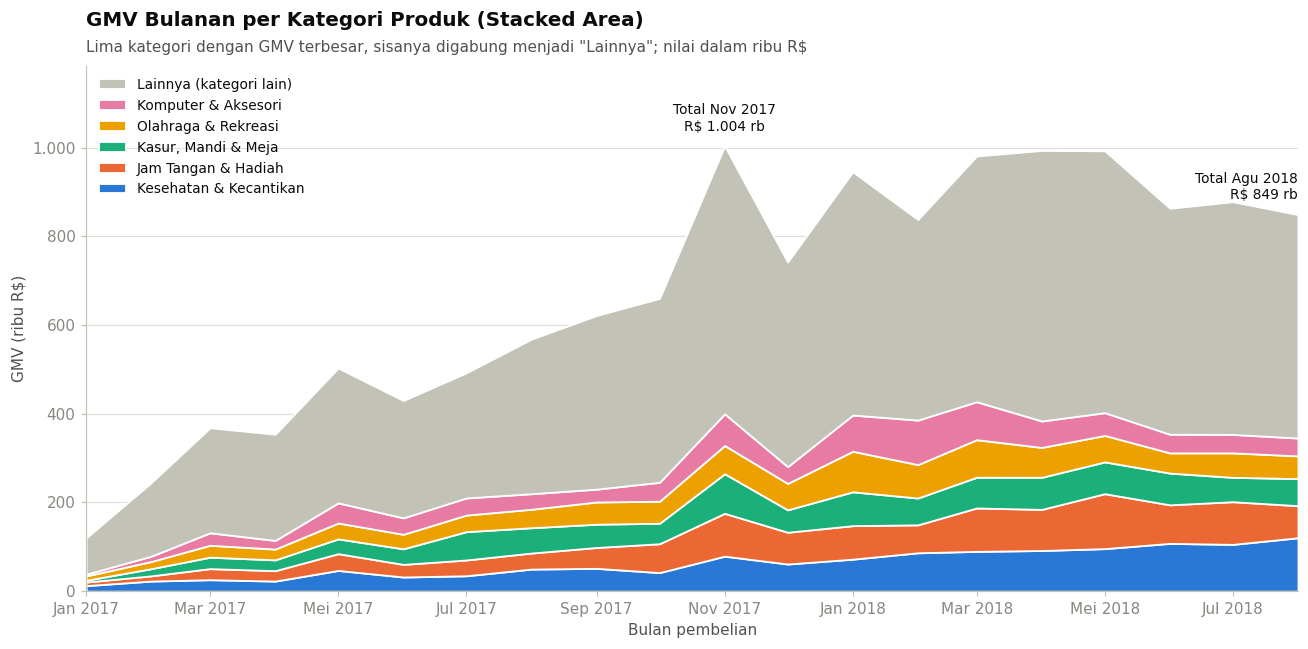

In [31]:
TOP_N_AREA = 5
top_categories = category_totals.index[:TOP_N_AREA].tolist()

# Warna dikunci per kategori dan dipakai ulang di grafik lain
CATEGORY_COLORS = dict(zip(top_categories, PALETTE))

area_data = monthly_category[top_categories].copy()
area_data['Lainnya'] = monthly_category.drop(columns=top_categories).sum(axis=1)
area_k = area_data / 1e3   # dalam ribu R$

area_colors = [CATEGORY_COLORS[c] for c in top_categories] + [COLOR_OTHER]
area_labels = [label_kategori(c) for c in top_categories] + ['Lainnya (kategori lain)']

fig, ax = plt.subplots(figsize=(12, 6))
ax.stackplot(area_k.index, area_k.T.to_numpy(), labels=area_labels, colors=area_colors,
             edgecolor='white', linewidth=1.2)

# Label total GMV pada bulan puncak dan bulan terakhir
total_k = area_k.sum(axis=1)
for month, align in {total_k.idxmax(): 'center', total_k.index[-1]: 'right'}.items():
    ax.annotate(f'Total {format_bulan(month)}\nR$ {fmt_id(total_k[month])} rb',
                xy=(mdates.date2num(month), total_k[month]), xytext=(0, 8),
                textcoords='offset points', ha=align, va='bottom', fontsize=9)

# Legenda dibalik agar urutannya sama dengan urutan tumpukan (atas ke bawah)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper left', fontsize=9)

ax.set_ylim(0, total_k.max() * 1.18)
ax.set_xlim(area_k.index[0], area_k.index[-1])
ax.grid(axis='x', visible=False)
atur_sumbu_bulan(ax, area_k.index, interval=2)
atur_sumbu_angka(ax)
ax.set_xlabel('Bulan pembelian')
ax.set_ylabel('GMV (ribu R$)')
beri_judul(ax, 'GMV Bulanan per Kategori Produk (Stacked Area)',
           'Lima kategori dengan GMV terbesar, sisanya digabung menjadi "Lainnya"; nilai dalam ribu R$')
plt.tight_layout()
plt.show()

In [32]:
# Tabel pendamping area plot: total dan porsi GMV, serta perbandingan awal vs akhir periode
area_table = pd.DataFrame({
    'kategori': area_labels,
    'gmv_total': area_data.sum().values,
})
area_table['porsi_%'] = area_table['gmv_total'] / area_table['gmv_total'].sum() * 100
area_table[f'porsi_{format_bulan(area_data.index[0])}_%'] = (
    area_data.iloc[0] / area_data.iloc[0].sum() * 100).values
area_table[f'porsi_{format_bulan(area_data.index[-1])}_%'] = (
    area_data.iloc[-1] / area_data.iloc[-1].sum() * 100).values
display(area_table.style.format({'gmv_total': 'R$ {:,.0f}', 'porsi_%': '{:.1f}',
                                 area_table.columns[3]: '{:.1f}', area_table.columns[4]: '{:.1f}'}))

gmv_m = monthly['gmv']
print(f'GMV {format_bulan(gmv_m.index[0])} : R$ {gmv_m.iloc[0]:,.0f}')
print(f'GMV tertinggi : {format_bulan(gmv_m.idxmax())}, R$ {gmv_m.max():,.0f}')
print(f'GMV {format_bulan(gmv_m.index[-1])} : R$ {gmv_m.iloc[-1]:,.0f}')
print(f"Rata-rata GMV per bulan 2017 : R$ {gmv_m[gmv_m.index.year == 2017].mean():,.0f}")
print(f"Rata-rata GMV per bulan 2018 : R$ {gmv_m[gmv_m.index.year == 2018].mean():,.0f}")

,kategori,gmv_total,porsi_%,porsi_Jan 2017_%,porsi_Agu 2018_%
0,Kesehatan & Kecantikan,"R$ 1,251,146",9.3,10.5,14.2
1,Jam Tangan & Hadiah,"R$ 1,194,825",8.9,6.7,8.5
2,"Kasur, Mandi & Meja","R$ 1,035,485",7.7,3.3,7.2
3,Olahraga & Rekreasi,"R$ 977,729",7.3,8.1,6.0
4,Komputer & Aksesori,"R$ 902,923",6.7,3.3,4.7
5,Lainnya (kategori lain),"R$ 8,087,423",60.1,68.2,59.3


GMV Jan 2017 : R$ 120,098
GMV tertinggi : Nov 2017, R$ 1,003,862
GMV Agu 2018 : R$ 848,860
Rata-rata GMV per bulan 2017 : R$ 509,041
Rata-rata GMV per bulan 2018 : R$ 917,630


**Interpretasi (menjawab pertanyaan 2).**
- **GMV bergerak searah dengan jumlah pesanan.** GMV bulanan naik dari R$ 120.098 pada Januari 2017 ke puncak R$ 1.003.862 pada November 2017. Rata-rata GMV per bulan meningkat dari sekitar R$ 509 ribu pada 2017 menjadi sekitar R$ 918 ribu pada 2018.
- **Maret sampai Mei 2018 adalah level tertinggi tanpa momen promosi besar.** GMV tiga bulan ini (R$ 981 ribu sampai R$ 994 ribu, lihat tabel bulanan di Bagian 5.6) hampir menyamai puncak November 2017. Bedanya, puncak November ditopang satu momen promosi, sedangkan Maret sampai Mei 2018 merupakan level penjualan yang bertahan selama tiga bulan.
- **Sedikit melandai pada Juni sampai Agustus 2018**, dengan GMV di kisaran R$ 849 ribu sampai R$ 878 ribu per bulan.
- **Penjualan tersebar di banyak kategori.** Lima kategori terbesar hanya menyumbang 39,9% GMV, sedangkan 60,1% sisanya datang dari 69 kategori lain. Lapisan abu-abu "Lainnya" yang tebal pada grafik menggambarkan hal ini. Di antara lima kategori teratas, porsi Kesehatan & Kecantikan naik dari 10,5% (Januari 2017) menjadi 14,2% (Agustus 2018). Pada bulan terakhir itu porsinya jauh di atas empat kategori teratas lainnya, yang berkisar 4,7% sampai 8,5%.

### 6.3 *Multiple Time Series*: perbandingan tiga kategori teratas
Tiga kategori dengan GMV terbesar dibandingkan pada satu grafik dengan periode dan granularitas yang sama (bulanan). Identitas setiap garis ditulis langsung di ujung kanan garis (*direct labeling*), sehingga pembaca tidak perlu bolak-balik melihat legenda. Membatasi jumlah garis menjadi tiga juga mencegah grafik berubah menjadi *spaghetti chart*.

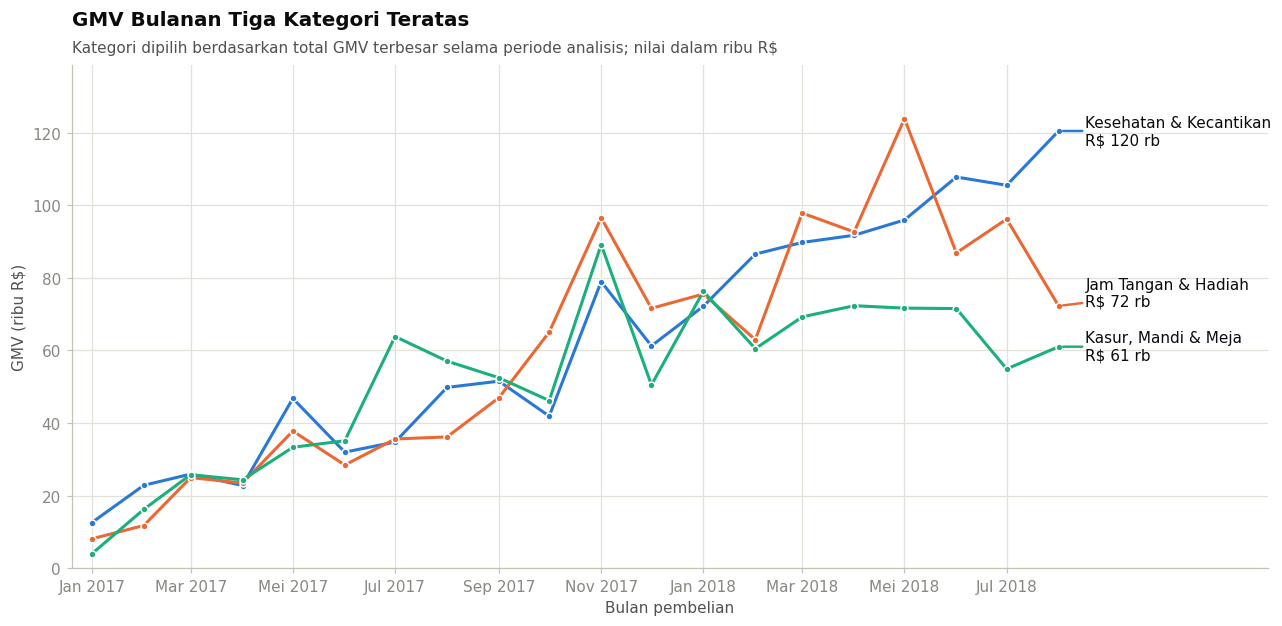

In [33]:
TOP_N_LINES = 3
line_categories = top_categories[:TOP_N_LINES]
multi_k = monthly_category[line_categories] / 1e3   # dalam ribu R$

fig, ax = plt.subplots(figsize=(12, 5.8))
for cat in line_categories:
    ax.plot(multi_k.index, multi_k[cat], color=CATEGORY_COLORS[cat], lw=2,
            marker='o', ms=4.5, markeredgecolor='white', markeredgewidth=1)

# Direct labeling di ujung setiap garis (tanpa legenda)
last_month = multi_k.index[-1]
end_values = multi_k.loc[last_month, line_categories].to_numpy()
end_texts = [f'{label_kategori(c)}\nR$ {fmt_id(v)} rb' for c, v in zip(line_categories, end_values)]
label_ujung_garis(ax, last_month, end_values, end_texts,
                  [CATEGORY_COLORS[c] for c in line_categories],
                  jarak_min=multi_k.max().max() * 0.12, geser_hari=16)

ax.set_xlim(multi_k.index[0] - pd.Timedelta(days=12), last_month + pd.Timedelta(days=125))
ax.set_ylim(0, multi_k.max().max() * 1.12)
atur_sumbu_bulan(ax, multi_k.index, interval=2)
atur_sumbu_angka(ax)
ax.set_xlabel('Bulan pembelian')
ax.set_ylabel('GMV (ribu R$)')
beri_judul(ax, 'GMV Bulanan Tiga Kategori Teratas',
           'Kategori dipilih berdasarkan total GMV terbesar selama periode analisis; nilai dalam ribu R$')
plt.tight_layout()
plt.show()

In [34]:
# Angka pendukung: perbandingan tiap kategori pada bulan-bulan yang sama antartahun.
# Tahun terakhir hanya berisi sebagian bulan, jadi dibandingkan dengan bulan yang sama tahun sebelumnya.
last_year = monthly_category.index[-1].year
months_last_year = monthly_category.index[monthly_category.index.year == last_year].month
mask_prev = ((monthly_category.index.year == last_year - 1)
             & monthly_category.index.month.isin(months_last_year))
mask_curr = monthly_category.index.year == last_year
period_label = f'{BULAN_ID[months_last_year.min() - 1]}-{BULAN_ID[months_last_year.max() - 1]}'
col_prev, col_curr = f'gmv_{period_label}_{last_year - 1}', f'gmv_{period_label}_{last_year}'

rows = []
for cat in top_categories:
    s = monthly_category[cat]
    rows.append({
        'kategori': label_kategori(cat),
        col_prev: s[mask_prev].sum(),
        col_curr: s[mask_curr].sum(),
        'pertumbuhan_%': (s[mask_curr].sum() / s[mask_prev].sum() - 1) * 100,
        'bulan_puncak': format_bulan(s.idxmax()),
        'gmv_puncak': s.max(),
        'gmv_bulan_terakhir': s.iloc[-1],
        'terakhir_vs_puncak_%': (s.iloc[-1] / s.max() - 1) * 100,
    })
category_trend = pd.DataFrame(rows)
formats = {c: 'R$ {:,.0f}' for c in category_trend.columns if c.startswith('gmv')}
formats.update({'pertumbuhan_%': '{:+.1f}', 'terakhir_vs_puncak_%': '{:+.1f}'})
category_trend.style.format(formats)

,kategori,gmv_Jan-Agu_2017,gmv_Jan-Agu_2018,pertumbuhan_%,bulan_puncak,gmv_puncak,gmv_bulan_terakhir,terakhir_vs_puncak_%
0,Kesehatan & Kecantikan,"R$ 247,458","R$ 770,003",+211.2,Agu 2018,"R$ 120,476","R$ 120,476",+0.0
1,Jam Tangan & Hadiah,"R$ 206,284","R$ 708,306",+243.4,Mei 2018,"R$ 123,873","R$ 72,277",-41.7
2,"Kasur, Mandi & Meja","R$ 259,621","R$ 537,514",+107.0,Nov 2017,"R$ 89,173","R$ 61,036",-31.6
3,Olahraga & Rekreasi,"R$ 224,597","R$ 530,182",+136.1,Jan 2018,"R$ 91,368","R$ 51,190",-44.0
4,Komputer & Aksesori,"R$ 219,639","R$ 502,432",+128.8,Feb 2018,"R$ 100,368","R$ 40,269",-59.9


**Interpretasi (menjawab pertanyaan 3).**
- **Hingga Oktober 2017 ketiga kategori bergerak hampir seiring.** Nilai GMV bulanannya berdekatan dan garisnya berkali-kali bersilangan, dengan beberapa pengecualian kecil seperti lonjakan Kasur, Mandi & Meja pada Juli 2017.
- **November 2017 mengangkat ketiganya sekaligus.** Efek Black Friday terasa lintas kategori, bukan hanya pada satu jenis produk.
- **Mulai 2018 polanya berpisah.**
  - **Kesehatan & Kecantikan** tumbuh paling konsisten. GMV-nya naik hampir setiap bulan sepanjang 2018 dan mencapai titik tertinggi tepat di bulan terakhir (Agustus 2018, R$ 120.476).
  - **Jam Tangan & Hadiah** tumbuh paling cepat, dengan GMV Januari sampai Agustus 2018 naik 243,4% dibanding periode yang sama tahun 2017, tetapi juga paling fluktuatif. Puncaknya terjadi pada Mei 2018 (R$ 123.873), lalu turun 41,7% hingga Agustus 2018.
  - **Kasur, Mandi & Meja** tumbuh paling lambat di antara ketiganya (+107,0%) dan cenderung mendatar sepanjang 2018. Nilai tertingginya justru tercatat pada November 2017.
- Tabel di atas menunjukkan bahwa empat dari lima kategori teratas sudah melewati puncaknya, dengan GMV bulan terakhir 31,6% sampai 59,9% di bawah nilai puncak. Hanya Kesehatan & Kecantikan yang masih berada di titik tertinggi. Jadi, *plateau* GMV total pada 2018 bukan berarti semua kategori berhenti tumbuh. Yang terjadi adalah kategori yang masih tumbuh dan kategori yang melemah saling mengimbangi.

### 6.4 *Calendar Heatmap*: pola aktivitas transaksi
Heatmap utama memetakan **hari dalam seminggu** (baris) terhadap **bulan** (kolom). Nilai sel adalah rata-rata jumlah pesanan per hari, bukan total. Rata-rata dipakai karena jumlah hari Senin, Selasa, dan seterusnya tidak selalu sama di setiap bulan. Warna lebih gelap berarti aktivitas lebih tinggi.

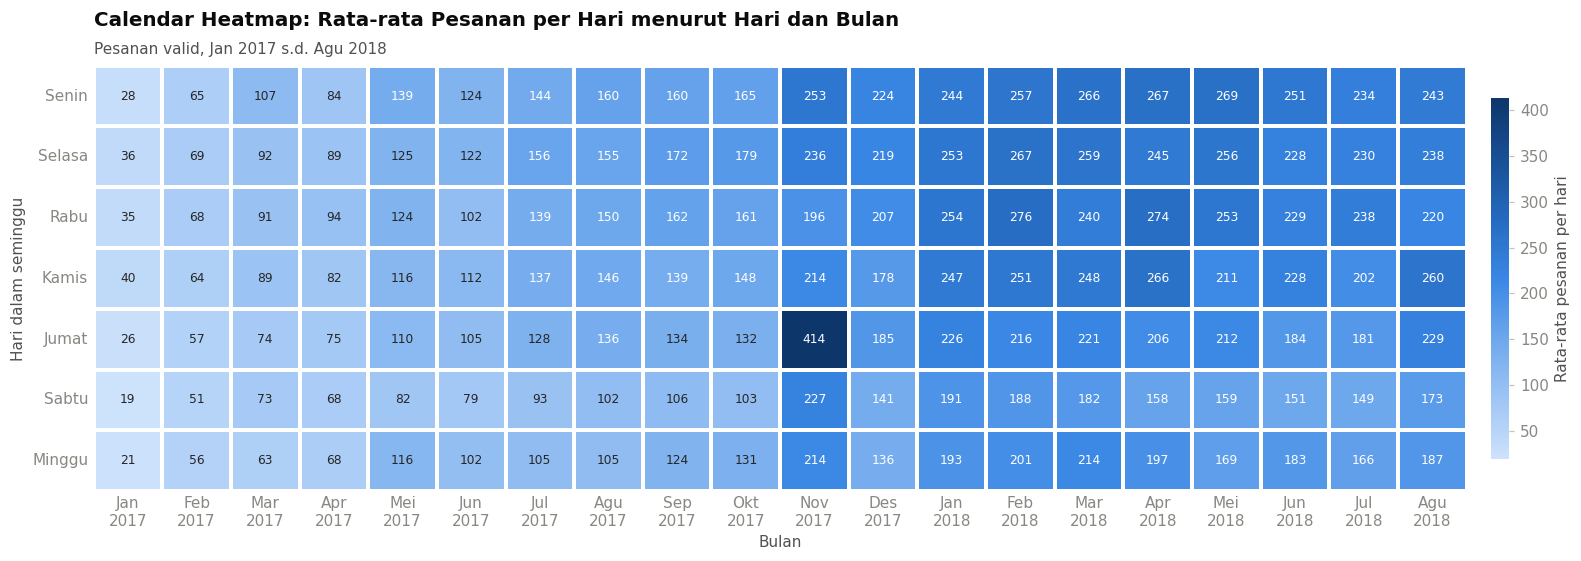

In [35]:
heat_source = daily.assign(hari=daily.index.dayofweek, bulan=daily.index.to_period('M'))
heat_pivot = heat_source.pivot_table(index='hari', columns='bulan',
                                     values='jumlah_order', aggfunc='mean')
heat_pivot.index = [HARI_ID[i] for i in heat_pivot.index]
# Label kolom dua baris (bulan di atas, tahun di bawah) agar tidak perlu diputar
heat_pivot.columns = [f'{BULAN_ID[p.month - 1]}\n{p.year}' for p in heat_pivot.columns]

fig, ax = plt.subplots(figsize=(16, 5.2))
sns.heatmap(heat_pivot, cmap=CMAP_BLUE, annot=True, fmt='.0f', annot_kws={'size': 8},
            linewidths=1.5, linecolor='white',
            cbar_kws={'label': 'Rata-rata pesanan per hari', 'shrink': 0.85, 'pad': 0.015},
            ax=ax)
ax.set_xlabel('Bulan')
ax.set_ylabel('Hari dalam seminggu')
ax.tick_params(axis='x', rotation=0, length=0)
ax.tick_params(axis='y', rotation=0, length=0)
ax.grid(False)
beri_judul(ax, 'Calendar Heatmap: Rata-rata Pesanan per Hari menurut Hari dan Bulan',
           f'Pesanan valid, {format_bulan(start_month)} s.d. {format_bulan(end_month)}')
plt.tight_layout()
plt.show()

Sebagai pelengkap, heatmap kalender harian di bawah menampilkan setiap tanggal sebagai satu kotak (kolom = minggu, baris = hari). Format ini memperlihatkan hari-hari tertentu yang menonjol, sesuatu yang tidak terlihat pada rata-rata bulanan. Skala warna dibatasi pada persentil ke-99 agar satu hari ekstrem tidak membuat seluruh kotak lain tampak pucat. Kotak abu-abu muda adalah tanggal di luar periode analisis.

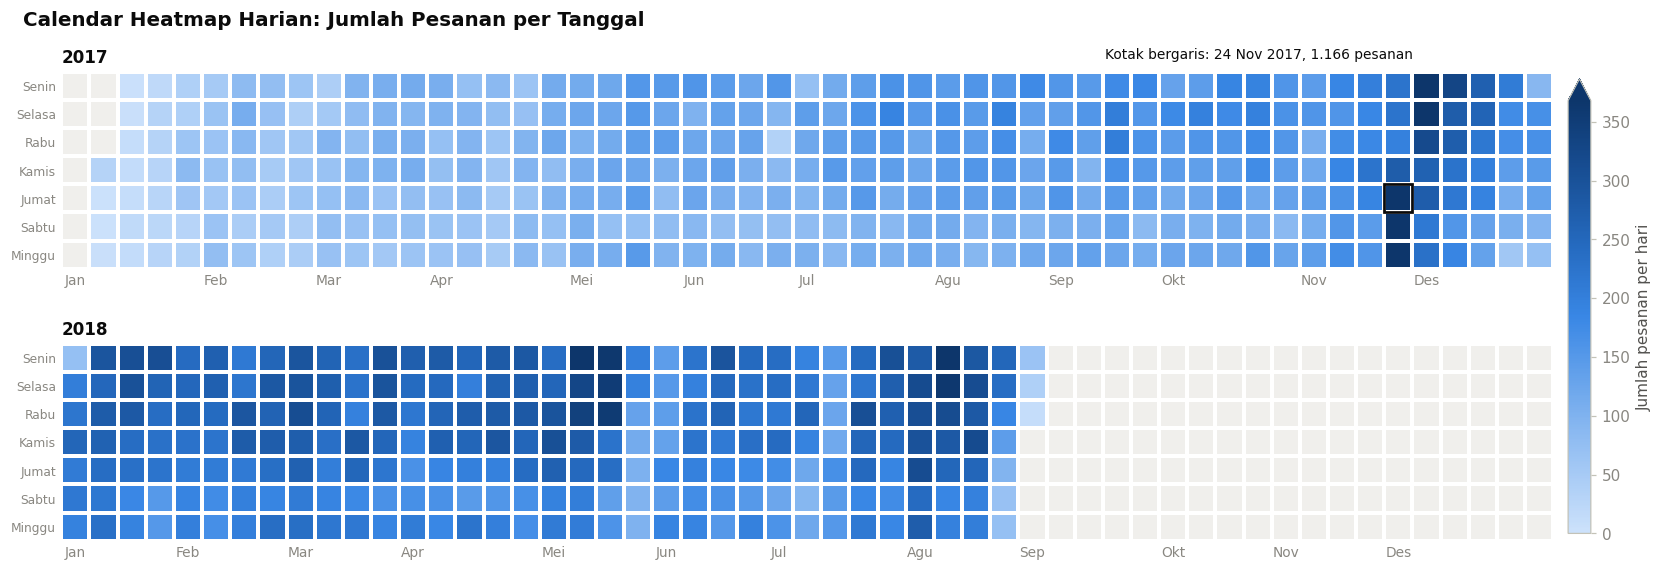

In [36]:
def gambar_kalender(ax, series, year, vmin, vmax):
    """Calendar heatmap satu tahun: kolom = minggu ke-, baris = hari (Senin di atas)."""
    days = pd.date_range(f'{year}-01-01', f'{year}-12-31', freq='D')
    values = series.reindex(days).to_numpy()            # NaN di luar periode analisis
    offset = days[0].dayofweek                          # posisi 1 Januari dalam minggu
    week_idx = (np.arange(len(days)) + offset) // 7
    grid = np.full((7, week_idx.max() + 1), np.nan)
    grid[days.dayofweek.to_numpy(), week_idx] = values

    cmap = copy.copy(CMAP_BLUE)
    cmap.set_bad('#f0efec')                              # abu-abu muda = tidak ada data
    mesh = ax.pcolormesh(np.ma.masked_invalid(grid), cmap=cmap, vmin=vmin, vmax=vmax,
                         edgecolors='white', linewidth=1.5)
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.set_yticks(np.arange(7) + 0.5)
    ax.set_yticklabels(HARI_ID, fontsize=8)
    month_starts = pd.date_range(f'{year}-01-01', periods=12, freq='MS')
    ax.set_xticks([(d.dayofyear - 1 + offset) // 7 + 0.5 for d in month_starts])
    ax.set_xticklabels(BULAN_ID, fontsize=9)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(str(year), loc='left', fontsize=11, pad=6)
    return mesh, offset


orders_daily = daily['jumlah_order']
vmax = orders_daily.quantile(0.99)
years = sorted(orders_daily.index.year.unique())

fig, axes = plt.subplots(len(years), 1, figsize=(15, 2.3 * len(years) + 0.6),
                         layout='constrained')
axes = np.atleast_1d(axes)
offsets = {}
for ax, year in zip(axes, years):
    mesh, offsets[year] = gambar_kalender(ax, orders_daily, year, vmin=0, vmax=vmax)

# Tandai tanggal dengan pesanan terbanyak: kotaknya diberi garis tepi gelap
busiest_day = orders_daily.idxmax()
ax_busy = axes[years.index(busiest_day.year)]
cell_col = (busiest_day.dayofyear - 1 + offsets[busiest_day.year]) // 7
cell_row = busiest_day.dayofweek
ax_busy.add_patch(plt.Rectangle((cell_col, cell_row), 1, 1, fill=False,
                                edgecolor=INK_PRIMARY, lw=1.8))
ax_busy.text(cell_col + 1, -0.35,
             f'Kotak bergaris: {format_tanggal(busiest_day)}, {fmt_id(orders_daily.max())} pesanan',
             ha='right', va='bottom', fontsize=9)

cbar = fig.colorbar(mesh, ax=axes.tolist(), shrink=0.85, pad=0.01, extend='max')
cbar.set_label('Jumlah pesanan per hari')
fig.suptitle('Calendar Heatmap Harian: Jumlah Pesanan per Tanggal', x=0.01, ha='left',
             fontsize=13, fontweight='bold')
plt.show()

In [37]:
# Angka pendukung interpretasi heatmap
weekday_mean = daily.groupby(daily.index.dayofweek)['jumlah_order'].mean()
weekday_mean.index = HARI_ID
print('Rata-rata pesanan per hari menurut hari dalam seminggu:')
print(weekday_mean.round(1).to_string())

weekday_avg = weekday_mean.iloc[:5].mean()
weekend_avg = weekday_mean.iloc[5:].mean()
print(f'\nRata-rata Senin-Jumat : {weekday_avg:.1f} pesanan/hari')
print(f'Rata-rata Sabtu-Minggu: {weekend_avg:.1f} pesanan/hari ({weekend_avg / weekday_avg - 1:+.1%})')

print('\n5 tanggal dengan pesanan terbanyak:')
top_days = daily['jumlah_order'].nlargest(5).to_frame()
top_days['hari'] = [HARI_ID[d.dayofweek] for d in top_days.index]
print(top_days.to_string())

month_avg = daily['jumlah_order'].resample('MS').mean()
print(f'\nBulan dengan rata-rata harian tertinggi: {format_bulan(month_avg.idxmax())} '
      f'({month_avg.max():.1f} pesanan/hari)')

# Pekan (Senin-Minggu) dengan rata-rata pesanan terendah pada tahun terakhir data.
# Pekan terakhir tidak diikutkan karena terpotong oleh batas akhir data.
weekly_avg = daily['jumlah_order'].resample('W-SUN').mean()
weekly_last_year = weekly_avg[weekly_avg.index.year == daily.index[-1].year].iloc[:-1]
print(f'\nRata-rata pesanan per hari sepanjang {daily.index[-1].year}: {weekly_last_year.mean():.0f}')
print(f'3 pekan dengan rata-rata terendah pada {daily.index[-1].year} (tanggal = hari Minggu akhir pekan):')
print(weekly_last_year.nsmallest(3).round(0).to_string())

Rata-rata pesanan per hari menurut hari dalam seminggu:
Senin     185.3
Selasa    182.6
Rabu      178.0
Kamis     168.9
Jumat     161.7
Sabtu     124.7
Minggu    137.3

Rata-rata Senin-Jumat : 175.3 pesanan/hari
Rata-rata Sabtu-Minggu: 131.0 pesanan/hari (-25.3%)

5 tanggal dengan pesanan terbanyak:
            jumlah_order    hari
tanggal                         
2017-11-24          1166   Jumat
2017-11-25           498   Sabtu
2017-11-27           400   Senin
2017-11-26           387  Minggu
2017-11-28           376  Selasa

Bulan dengan rata-rata harian tertinggi: Nov 2017 (247.4 pesanan/hari)

Rata-rata pesanan per hari sepanjang 2018: 224
3 pekan dengan rata-rata terendah pada 2018 (tanggal = hari Minggu akhir pekan):
tanggal
2018-05-27    135.0
2018-07-15    141.0
2018-08-26    151.0


**Interpretasi (menjawab pertanyaan 4).**
- **Pola mingguan sangat konsisten.** Rata-rata pesanan tertinggi terjadi pada hari Senin (185,3 per hari), lalu menurun perlahan sampai Jumat (161,7). Sabtu menjadi hari tersepi (124,7). Secara keseluruhan, rata-rata pesanan di akhir pekan 25,3% lebih rendah daripada hari kerja. Pada heatmap, pola ini tampak sebagai baris Sabtu dan Minggu yang lebih terang di hampir setiap bulan.
- **Intensitas meningkat dari kiri ke kanan.** Warna sel makin gelap dari awal 2017 menuju 2018, sejalan dengan tren naik pada *line plot*.
- **November 2017 adalah periode paling padat.** Rata-rata harian November 2017 mencapai 247,4 pesanan, tertinggi di antara semua bulan. Sel Jumat November 2017 bernilai 414, jauh di atas sel lain, karena memuat tanggal 24 November 2017 (Black Friday) dengan 1.166 pesanan dalam sehari. Kalender harian memperlihatkan bahwa efeknya berlanjut beberapa hari: lima tanggal tersibuk di seluruh periode semuanya jatuh pada 24 sampai 28 November 2017.
- **Penurunan tajam pada akhir Mei 2018.** Kalender harian menampilkan kolom yang lebih terang di akhir Mei 2018. Pekan yang berakhir 27 Mei 2018 menjadi pekan dengan rata-rata pesanan terendah di tahun 2018. Periode ini bertepatan dengan mogok nasional pengemudi truk di Brazil yang dimulai 21 Mei 2018 dan mengganggu distribusi barang. Hubungan sebab-akibatnya tidak diuji di notebook ini, jadi perlu dibaca sebagai dugaan kontekstual.
- **Pola musiman tahunan belum dapat dipastikan.** Data hanya mencakup 20 bulan, sehingga bulan September sampai Desember baru teramati satu kali. Belum bisa disimpulkan apakah setiap November selalu menjadi bulan tersibuk.

## 7. Trend Analysis

### 7.1 Konsep *Moving Average*
*Moving Average* (MA) atau rata-rata bergerak menghaluskan *time series* dengan mengganti setiap titik menjadi rata-rata dari sejumlah titik terakhir. Jumlah titik tersebut disebut ukuran *window* ($w$). Notebook ini memakai *trailing moving average*, yaitu rata-rata dari hari ini dan $w-1$ hari sebelumnya:

$$MA_t = \frac{1}{w}\sum_{i=0}^{w-1} y_{t-i}$$

Fungsinya dalam analisis *time series*:
- **Meredam *noise***: fluktuasi acak dari hari ke hari ikut terbagi rata sehingga pola dasarnya lebih terlihat.
- **Menampakkan tren**: arah naik, turun, atau mendatar lebih mudah dibaca dari kurva yang halus.
- **Menghilangkan siklus tertentu**: *window* yang panjangnya sama dengan satu siklus akan menetralkan siklus tersebut. Contohnya, *window* 7 hari selalu memuat tepat satu Senin, satu Selasa, dan seterusnya, sehingga perbedaan hari kerja dan akhir pekan saling menutupi.

Dua ukuran *window* dibandingkan, yaitu **7 hari** (fluktuasi jangka pendek) dan **30 hari** (tren jangka panjang). Variabel yang dianalisis adalah **GMV harian** dalam ribu R$, karena pertanyaan analisis kelima menyangkut tren penjualan. Perhitungan memakai `pandas.Series.rolling(window).mean()` dengan pengaturan bawaan, sehingga nilai MA baru muncul setelah *window* terisi penuh. Hari-hari sebelumnya bernilai NaN.

### 7.2 Perhitungan *Moving Average*

In [38]:
trend = daily[['gmv']].copy()
trend['gmv_k'] = trend['gmv'] / 1e3                       # GMV harian dalam ribu R$
trend['ma7'] = trend['gmv_k'].rolling(window=7).mean()    # Moving Average 7 hari
trend['ma30'] = trend['gmv_k'].rolling(window=30).mean()  # Moving Average 30 hari

print(f"NaN pada MA 7 hari : {trend['ma7'].isna().sum()} hari pertama")
print(f"NaN pada MA 30 hari: {trend['ma30'].isna().sum()} hari pertama")
print(f"MA 30 hari pertama kali tersedia pada {format_tanggal(trend['ma30'].first_valid_index())}\n")

# Tampilkan baris awal untuk melihat kapan masing-masing MA mulai terisi
pd.concat([trend.head(8), trend.iloc[27:31]])[['gmv_k', 'ma7', 'ma30']].round(2)

NaN pada MA 7 hari : 6 hari pertama
NaN pada MA 30 hari: 29 hari pertama
MA 30 hari pertama kali tersedia pada 3 Feb 2017



,gmv_k,ma7,ma30
tanggal,,,
2017-01-05,0.40,NaN,NaN
2017-01-06,0.92,NaN,NaN
2017-01-07,1.35,NaN,NaN
2017-01-08,0.71,NaN,NaN
2017-01-09,0.67,NaN,NaN
2017-01-10,1.43,NaN,NaN
2017-01-11,2.61,1.16,NaN
2017-01-12,2.23,1.42,NaN
2017-02-01,8.10,9.46,NaN


### 7.3 *Overlay* data asli, MA 7 hari, dan MA 30 hari

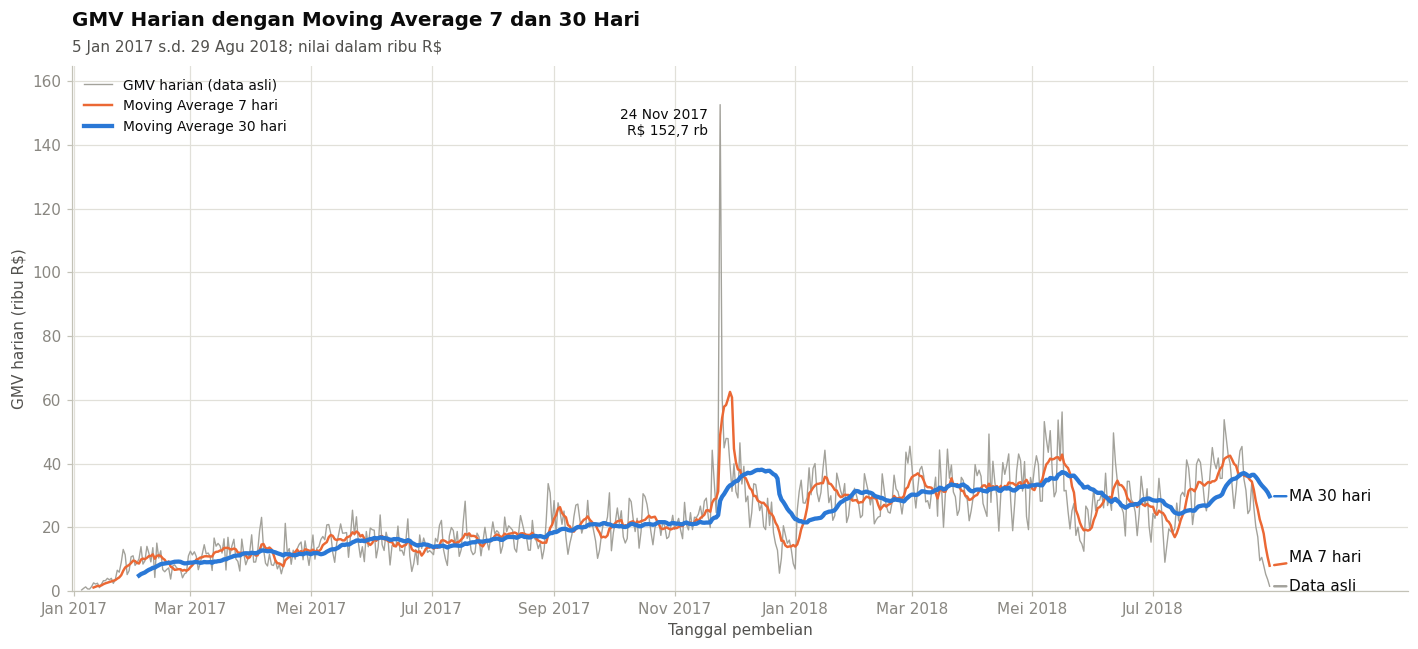

In [39]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(trend.index, trend['gmv_k'], color=COLOR_RAW, lw=0.9, label='GMV harian (data asli)')
ax.plot(trend.index, trend['ma7'], color=PALETTE[1], lw=1.6, label='Moving Average 7 hari')
ax.plot(trend.index, trend['ma30'], color=PALETTE[0], lw=2.8, label='Moving Average 30 hari')

# Tandai lonjakan tertinggi pada data asli
peak_day = trend['gmv_k'].idxmax()
ax.annotate(f'{format_tanggal(peak_day)}\nR$ {fmt_id(trend.loc[peak_day, "gmv_k"], 1)} rb',
            xy=(mdates.date2num(peak_day), trend.loc[peak_day, 'gmv_k']),
            xytext=(-8, -2), textcoords='offset points', ha='right', va='top', fontsize=9)

# Direct label di ujung kanan, ditambah legenda
end_day = trend.index[-1]
end_vals = trend.loc[end_day, ['gmv_k', 'ma7', 'ma30']].to_numpy(dtype=float)
label_ujung_garis(ax, end_day, end_vals, ['Data asli', 'MA 7 hari', 'MA 30 hari'],
                  [COLOR_RAW, PALETTE[1], PALETTE[0]], jarak_min=9, geser_hari=10)
ax.legend(loc='upper left', fontsize=9)

ax.set_xlim(trend.index[0] - pd.Timedelta(days=5), end_day + pd.Timedelta(days=70))
ax.set_ylim(0, trend['gmv_k'].max() * 1.08)
month_ticks = pd.date_range(trend.index[0].to_period('M').to_timestamp(), end_day, freq='MS')
atur_sumbu_bulan(ax, month_ticks, interval=2)
atur_sumbu_angka(ax)
ax.set_xlabel('Tanggal pembelian')
ax.set_ylabel('GMV harian (ribu R$)')
beri_judul(ax, 'GMV Harian dengan Moving Average 7 dan 30 Hari',
           f'{format_tanggal(trend.index[0])} s.d. {format_tanggal(end_day)}; nilai dalam ribu R$')
plt.tight_layout()
plt.show()

**Interpretasi.**
- **Data asli (abu-abu)** sangat bergerigi. Nilainya naik turun tajam dari hari ke hari, sebagian karena pola mingguan dan sebagian lagi karena *noise* acak. Lonjakan 24 November 2017 (R$ 152,7 ribu) membuat skala sumbu Y melebar jauh.
- **MA 7 hari (oranye)** sudah meredam pola mingguan, tetapi masih responsif terhadap perubahan jangka pendek. Kenaikan setelah Black Friday, penurunan menjelang akhir Desember 2017, dan penurunan di akhir Mei 2018 tetap terlihat jelas.
- **MA 30 hari (biru)** paling halus dan menunjukkan gambaran besarnya: naik bertahap sepanjang 2017, membentuk "punuk" sementara sekitar Black Friday, lalu bergerak mendatar selama 2018.
- **Ujung kanan grafik perlu dibaca hati-hati.** Data asli dan MA 7 hari anjlok pada beberapa hari terakhir (24 sampai 29 Agustus 2018), sementara data September 2018 hampir kosong. Penurunan ini lebih mungkin disebabkan batas waktu pengambilan data daripada turunnya permintaan secara nyata.

### 7.4 Perbandingan hasil *smoothing*
Dua potongan periode diperbesar untuk melihat perilaku masing-masing *window* lebih dekat:
- **Kiri**: sekitar Black Friday 2017, untuk melihat bagaimana tiap MA merespons lonjakan satu hari.
- **Kanan**: dua bulan pertama data, untuk melihat berapa banyak titik awal yang hilang (NaN) pada setiap *window*.

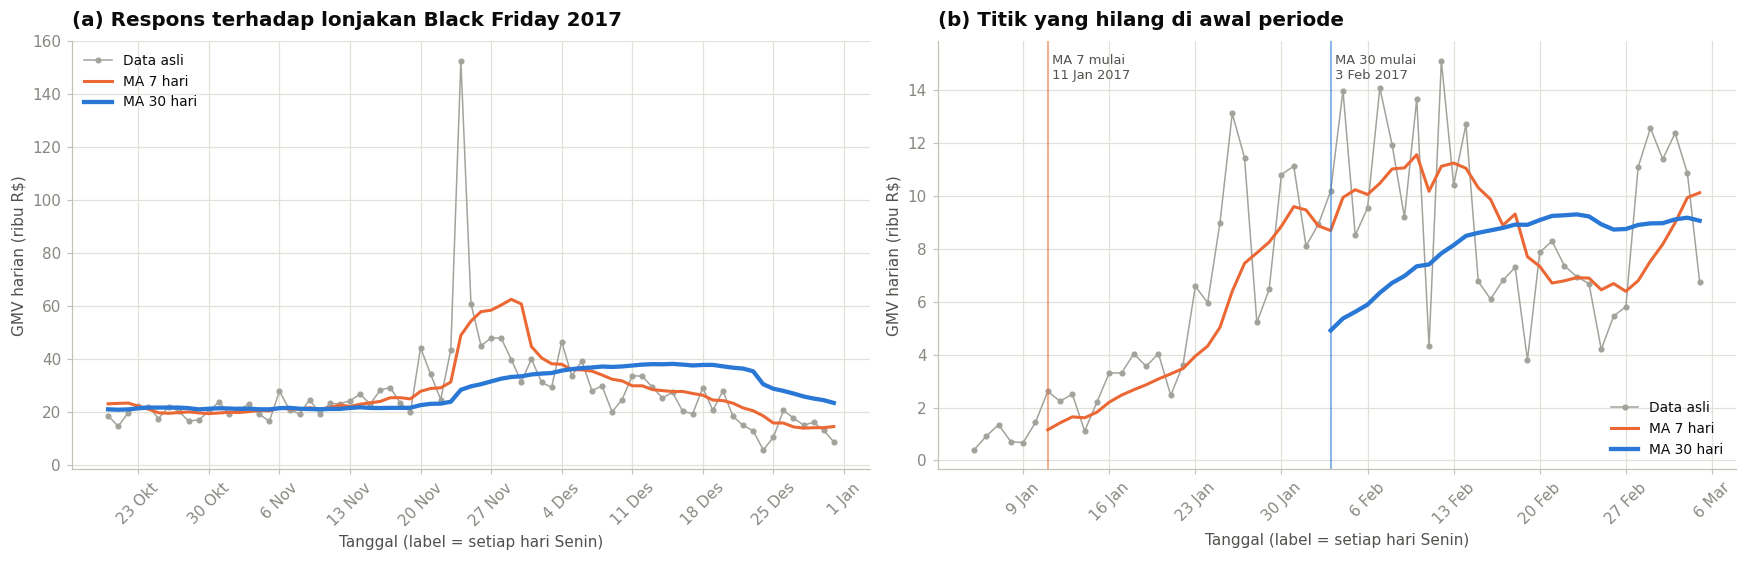

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
zooms = [
    (axes[0], '2017-10-20', '2017-12-31', '(a) Respons terhadap lonjakan Black Friday 2017'),
    (axes[1], trend.index[0], trend.index[0] + pd.Timedelta(days=59), '(b) Titik yang hilang di awal periode'),
]
for ax, start, end, title in zooms:
    part = trend.loc[start:end]
    ax.plot(part.index, part['gmv_k'], color=COLOR_RAW, lw=1, marker='o', ms=3,
            label='Data asli')
    ax.plot(part.index, part['ma7'], color=PALETTE[1], lw=2, label='MA 7 hari')
    ax.plot(part.index, part['ma30'], color=PALETTE[0], lw=2.8, label='MA 30 hari')
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda x, pos: f'{mdates.num2date(x).day} {BULAN_ID[mdates.num2date(x).month - 1]}'))
    ax.tick_params(axis='x', rotation=45)
    atur_sumbu_angka(ax)
    ax.set_xlabel('Tanggal (label = setiap hari Senin)')
    ax.set_ylabel('GMV harian (ribu R$)')
    ax.legend(loc='upper left' if ax is axes[0] else 'lower right', fontsize=9)
    beri_judul(ax, title)

# Tandai tanggal pertama MA 7 dan MA 30 tersedia pada panel kanan
for col, color, name in [('ma7', PALETTE[1], 'MA 7'), ('ma30', PALETTE[0], 'MA 30')]:
    first_valid = trend[col].first_valid_index()
    axes[1].axvline(first_valid, color=color, lw=1, alpha=0.7)
    axes[1].text(first_valid, axes[1].get_ylim()[1] * 0.97, f' {name} mulai\n {format_tanggal(first_valid)}',
                 fontsize=8.5, va='top', color=INK_SECONDARY)

plt.tight_layout()
plt.show()

In [41]:
def kekasaran(series):
    """Rata-rata perubahan absolut dari satu hari ke hari berikutnya (makin kecil = makin halus)."""
    return series.diff().abs().mean()


rows = []
for name, series in [('Data asli', trend['gmv_k']),
                     ('MA 7 hari', trend['ma7']),
                     ('MA 30 hari', trend['ma30'])]:
    rows.append({
        'series': name,
        'jumlah_NaN': int(series.isna().sum()),
        'persen_data_hilang': series.isna().mean() * 100,
        'rata2_perubahan_harian_abs': kekasaran(series),
        'standar_deviasi': series.std(),
        'nilai_maks': series.max(),
        'tanggal_nilai_maks': format_tanggal(series.idxmax()),
    })
comparison = pd.DataFrame(rows).set_index('series')
comparison.round(2)

,jumlah_NaN,persen_data_hilang,rata2_perubahan_harian_abs,standar_deviasi,nilai_maks,tanggal_nilai_maks
series,,,,,,
Data asli,0,0.00,5.36,12.37,152.65,24 Nov 2017
MA 7 hari,6,1.00,0.87,10.22,62.53,29 Nov 2017
MA 30 hari,29,4.82,0.30,8.75,38.15,15 Des 2017


**Interpretasi: perbandingan MA 7 hari dan MA 30 hari**

| Aspek | MA 7 hari | MA 30 hari |
|---|---|---|
| Data awal yang hilang (NaN) | 6 hari (1,0%) | 29 hari (4,8%) |
| Rata-rata perubahan dari hari ke hari | 0,87 ribu R$ (84% lebih kecil dari data asli) | 0,30 ribu R$ (94% lebih kecil) |
| Nilai maksimum | 62,5 ribu R$ pada 29 Nov 2017 | 38,1 ribu R$ pada 15 Des 2017 |
| Paling cocok untuk | Fluktuasi jangka pendek dan reaksi terhadap kejadian | Tren jangka panjang |

**Fungsi *moving average* di sini** adalah memisahkan "sinyal" dari "*noise*". Data GMV harian bercampur antara tren, pola mingguan, lonjakan promosi, dan fluktuasi acak. Merata-ratakan beberapa hari membuat komponen acak saling meniadakan, sehingga arah pergerakan yang sebenarnya lebih mudah dibaca.

**Mengapa *window* lebih besar menghasilkan kurva lebih halus?** Setiap titik MA adalah rata-rata dari $w$ hari, dan bobot setiap hari hanya $1/w$. Makin besar $w$, makin kecil pengaruh satu hari terhadap hasilnya. Lonjakan Black Friday menyumbang 1/7 bagian pada MA 7 hari, tetapi hanya 1/30 bagian pada MA 30 hari. Itulah sebabnya puncak 152,7 ribu R$ pada data asli diredam menjadi 62,5 ribu R$ oleh MA 7 hari dan tinggal 38,1 ribu R$ oleh MA 30 hari. Rata-rata perubahan dari hari ke hari pun turun dari 5,36 menjadi 0,87, lalu 0,30 ribu R$.

**Trade-off penggunaan *window* besar**
1. **Lebih banyak data awal yang hilang.** Dengan pengaturan bawaan `rolling(window)`, MA baru dapat dihitung setelah tersedia $w$ data. MA 7 hari kehilangan 6 hari pertama, sedangkan MA 30 hari kehilangan 29 hari pertama dan baru muncul pada 3 Februari 2017 (panel b). Pada *time series* yang pendek, kehilangan ini cukup berarti.
2. **Respons terlambat (*lag*).** *Trailing moving average* hanya melihat ke belakang. Panel (a) memperlihatkan MA 7 hari memuncak 5 hari setelah Black Friday, sedangkan MA 30 hari baru memuncak 21 hari setelahnya. MA 30 hari bahkan anjlok mendadak sekitar 24 Desember 2017. Penyebabnya bukan penurunan penjualan pada hari itu. Tanggal 24 November sudah keluar dari *window*, jadi nilai lonjakannya tidak lagi ikut dirata-ratakan.
3. **Kejadian penting bisa tersamarkan.** Lonjakan satu hari yang sangat besar hampir kehilangan bentuknya pada MA 30 hari. Efeknya justru menyebar menjadi "punuk" selama sebulan dan dapat disalahartikan sebagai kenaikan penjualan yang bertahan lama.

**Window mana yang lebih sesuai?** MA 7 hari lebih tepat untuk memantau fluktuasi jangka pendek, misalnya mengevaluasi dampak kampanye atau gangguan operasional dalam hitungan minggu. Panjang 7 hari juga pas dengan satu siklus mingguan, sehingga perbedaan hari kerja dan akhir pekan ternetralkan tanpa menghaluskan terlalu banyak. MA 30 hari lebih tepat untuk membaca tren jangka panjang, yaitu menilai apakah penjualan sedang tumbuh, stagnan, atau menurun dari bulan ke bulan.

### 7.5 Interpretasi tren berdasarkan MA 30 hari
Nilai MA 30 hari pada beberapa titik waktu dipakai untuk membaca arah tren jangka panjang secara kuantitatif.

In [42]:
# Ambil nilai MA 30 pada hari terakhir setiap kuartal, ditambah hari terakhir data
month_starts = pd.date_range(trend.index[0], trend.index[-1], freq='MS')
quarter_ends = [d - pd.Timedelta(days=1) for d in month_starts if d.month in (1, 4, 7, 10)]
checkpoints = [d for d in quarter_ends if pd.notna(trend.loc[d, 'ma30'])]
checkpoints.append(trend.index[-1])
ma30_points = trend.loc[checkpoints, ['ma30']].copy()
ma30_points.index = [format_tanggal(d) for d in ma30_points.index]
ma30_points['perubahan_vs_titik_sebelumnya_%'] = ma30_points['ma30'].pct_change() * 100
display(ma30_points.round(2))

ma30_max_day = trend['ma30'].idxmax()
print(f"MA 30 tertinggi: {format_tanggal(ma30_max_day)} (R$ {trend['ma30'].max():.1f} rb per hari)")

ma30_last_year = trend.loc[trend.index.year == trend.index[-1].year, 'ma30']
print(f'Rentang MA 30 pada {trend.index[-1].year}: {ma30_last_year.min():.1f} '
      f'({format_tanggal(ma30_last_year.idxmin())}) s.d. {ma30_last_year.max():.1f} '
      f'({format_tanggal(ma30_last_year.idxmax())}) ribu R$ per hari')

# Hari-hari terakhir data: dipakai untuk memeriksa penurunan di ujung kanan grafik
print('\n10 hari terakhir data:')
print(daily[['jumlah_order', 'gmv']].tail(10).round(0).to_string())

,ma30,perubahan_vs_titik_sebelumnya_%
31 Mar 2017,11.86,NaN
30 Jun 2017,14.33,20.84
30 Sep 2017,20.71,44.54
31 Des 2017,23.41,13.00
31 Mar 2018,31.39,34.10
30 Jun 2018,28.78,-8.33
29 Agu 2018,29.80,3.55


MA 30 tertinggi: 15 Des 2017 (R$ 38.1 rb per hari)
Rentang MA 30 pada 2018: 21.6 (7 Jan 2018) s.d. 37.4 (16 Mei 2018) ribu R$ per hari

10 hari terakhir data:
            jumlah_order      gmv
tanggal                          
2018-08-20           252  34480.0
2018-08-21           239  26323.0
2018-08-22           186  20297.0
2018-08-23           142  17031.0
2018-08-24            97   9586.0
2018-08-25            69  10599.0
2018-08-26            73   8071.0
2018-08-27            66   5346.0
2018-08-28            39   3674.0
2018-08-29            11   1546.0


**Interpretasi (menjawab pertanyaan 5).** Berdasarkan MA 30 hari, kecenderungan tren penjualan terbagi menjadi tiga fase.
1. **Fase pertumbuhan (2017).** MA 30 hari naik dari 11,86 ribu R$ per hari pada akhir Maret 2017 menjadi 23,41 ribu R$ pada akhir Desember 2017, atau hampir dua kali lipat dalam sembilan bulan. Kenaikan antarkuartal paling tajam terjadi pada kuartal ketiga 2017 (+44,5%).
2. **Lonjakan sementara (akhir November sampai Desember 2017).** Nilai MA 30 hari tertinggi, 38,1 ribu R$, muncul pada 15 Desember 2017. Angka ini terangkat oleh Black Friday yang masih berada di dalam *window*, bukan karena level penjualan normal sudah setinggi itu.
3. **Fase stabil (2018).** MA 30 hari naik lagi ke 31,39 ribu R$ pada akhir Maret 2018, turun 8,3% menjadi 28,78 ribu R$ pada akhir Juni 2018, dan berada di 29,80 ribu R$ pada hari terakhir data. Sepanjang 2018 nilainya hanya bergerak di kisaran 21,6 sampai 37,4 ribu R$ per hari, tanpa arah naik yang jelas. Dengan kata lain, setelah kuartal pertama 2018 penjualan berhenti tumbuh dan bertahan di level sekitar 2,5 kali lebih tinggi daripada Maret 2017.

Nilai pada hari terakhir sedikit tertekan oleh anjloknya pesanan pada 24 sampai 29 Agustus 2018 (tabel 10 hari terakhir di atas). Untuk membaca level akhir, titik akhir Juni 2018 lebih aman dijadikan acuan.

### 7.6 Analisis tambahan: *fitting* model matematika
Sebagai pelengkap *Moving Average*, dua model polinomial dipasang pada GMV harian dengan `numpy.polyfit`:
- **Linear** (derajat 1): menggambarkan arah tren rata-rata dalam satu garis lurus.
- **Kuadratik** (derajat 2): memungkinkan kurva melengkung, sehingga bisa menangkap pertumbuhan yang melambat.

Sumbu X model adalah urutan hari sejak tanggal pertama (0, 1, 2, ...). Kualitas kecocokan diukur dengan $R^2$.

In [43]:
x_days = np.arange(len(trend))
y_gmv = trend['gmv_k'].to_numpy()

coef_linear = np.polyfit(x_days, y_gmv, deg=1)
coef_quad = np.polyfit(x_days, y_gmv, deg=2)
trend['fit_linear'] = np.polyval(coef_linear, x_days)
trend['fit_kuadratik'] = np.polyval(coef_quad, x_days)


def r_squared(actual, predicted):
    """Koefisien determinasi R^2."""
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - actual.mean()) ** 2)
    return 1 - ss_res / ss_tot


r2_linear = r_squared(y_gmv, trend['fit_linear'].to_numpy())
r2_quad = r_squared(y_gmv, trend['fit_kuadratik'].to_numpy())
vertex_day = -coef_quad[1] / (2 * coef_quad[0])          # titik puncak/lembah parabola
vertex_date = trend.index[0] + pd.Timedelta(days=float(vertex_day))

print(f'Model linear    : y = {coef_linear[0]:.4f}x + {coef_linear[1]:.2f}   (R^2 = {r2_linear:.3f})')
print(f'  kemiringan    : +R$ {coef_linear[0] * 1000:,.0f} per hari, '
      f'atau +R$ {coef_linear[0] * 1000 * 30:,.0f} GMV harian setiap 30 hari')
print(f'Model kuadratik : y = {coef_quad[0]:.6f}x^2 + {coef_quad[1]:.4f}x + {coef_quad[2]:.2f}'
      f'   (R^2 = {r2_quad:.3f})')
print(f'  koefisien x^2 {"negatif (kurva cekung, pertumbuhan melambat)" if coef_quad[0] < 0 else "positif"}')
print(f'  puncak parabola: hari ke-{vertex_day:.0f} ({format_tanggal(vertex_date)})')

Model linear    : y = 0.0451x + 8.78   (R^2 = 0.403)
  kemiringan    : +R$ 45 per hari, atau +R$ 1,354 GMV harian setiap 30 hari
Model kuadratik : y = -0.000098x^2 + 0.1041x + 2.88   (R^2 = 0.449)
  koefisien x^2 negatif (kurva cekung, pertumbuhan melambat)
  puncak parabola: hari ke-530 (19 Jun 2018)


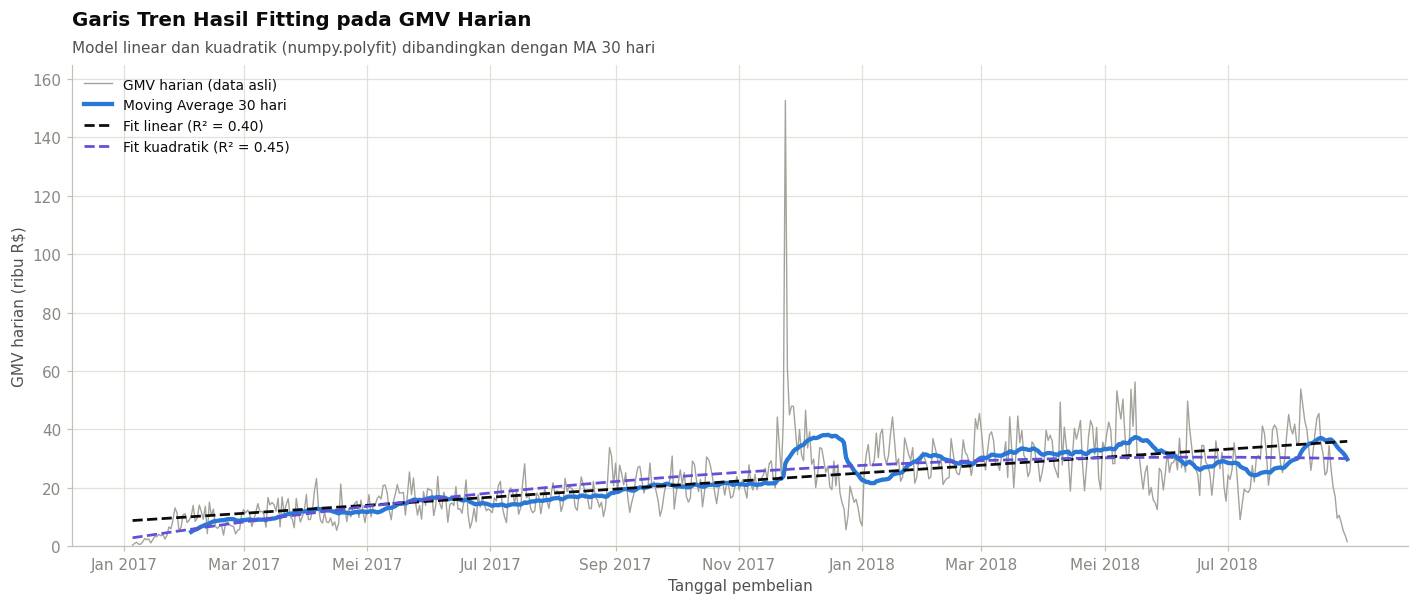

In [44]:
fig, ax = plt.subplots(figsize=(13, 5.6))
ax.plot(trend.index, trend['gmv_k'], color=COLOR_RAW, lw=0.9, label='GMV harian (data asli)')
ax.plot(trend.index, trend['ma30'], color=PALETTE[0], lw=2.8, label='Moving Average 30 hari')
ax.plot(trend.index, trend['fit_linear'], color=INK_PRIMARY, lw=1.8, ls='--',
        label=f'Fit linear (R² = {r2_linear:.2f})')
ax.plot(trend.index, trend['fit_kuadratik'], color=COLOR_FIT, lw=1.8, ls='--',
        label=f'Fit kuadratik (R² = {r2_quad:.2f})')
ax.legend(loc='upper left', fontsize=9)
ax.set_ylim(0, trend['gmv_k'].max() * 1.08)
atur_sumbu_bulan(ax, month_ticks, interval=2)
atur_sumbu_angka(ax)
ax.set_xlabel('Tanggal pembelian')
ax.set_ylabel('GMV harian (ribu R$)')
beri_judul(ax, 'Garis Tren Hasil Fitting pada GMV Harian',
           'Model linear dan kuadratik (numpy.polyfit) dibandingkan dengan MA 30 hari')
plt.tight_layout()
plt.show()

**Interpretasi.**
- **Model linear** memiliki kemiringan positif sebesar 0,0451 ribu R$ per hari. Artinya, secara rata-rata GMV harian bertambah sekitar R$ 45 setiap hari, atau sekitar R$ 1.354 setiap 30 hari. Nilai $R^2$ = 0,40 berarti garis lurus hanya menjelaskan sekitar 40% variasi GMV harian, wajar untuk data harian yang penuh *noise*.
- **Model kuadratik** sedikit lebih cocok ($R^2$ = 0,45). Koefisien $x^2$ bernilai negatif sehingga kurvanya cekung ke bawah, dengan puncak parabola sekitar 19 Juni 2018. Bentuk ini sejalan dengan pembacaan MA 30 hari: tumbuh cepat pada 2017, lalu melambat dan mendatar pada 2018.
- Di ujung kanan, garis linear berada di atas MA 30 hari karena model memaksa pertumbuhan terus berlanjut, padahal data 2018 sudah mendatar. Oleh sebab itu, model linear tidak tepat dipakai untuk memproyeksikan penjualan ke depan tanpa pertimbangan lain. *Fitting* di bagian ini hanya pelengkap, sedangkan analisis tren utama tetap bertumpu pada *Moving Average*.

## 8. Key Findings
Sel berikut merangkum angka-angka yang menjadi dasar setiap temuan, sehingga setiap *insight* dapat ditelusuri ke hasil perhitungan.

In [45]:
# 1) Perbandingan bulan yang sama antartahun (year-over-year)
last_year = monthly.index[-1].year
months_last_year = monthly.index[monthly.index.year == last_year].month
prev_mask = (monthly.index.year == last_year - 1) & monthly.index.month.isin(months_last_year)
curr_mask = monthly.index.year == last_year
period_label = f'{BULAN_ID[months_last_year.min() - 1]}-{BULAN_ID[months_last_year.max() - 1]}'
yoy = pd.DataFrame({
    f'{period_label} {last_year - 1}': monthly.loc[prev_mask, ['jumlah_order', 'gmv', 'item_terjual']].sum(),
    f'{period_label} {last_year}': monthly.loc[curr_mask, ['jumlah_order', 'gmv', 'item_terjual']].sum(),
})
yoy['pertumbuhan_%'] = (yoy.iloc[:, 1] / yoy.iloc[:, 0] - 1) * 100
print('1) Perbandingan periode yang sama antartahun:')
display(yoy.round(1))

# 2) Lonjakan Black Friday dibanding 4 minggu sebelumnya
peak_order_day = daily['jumlah_order'].idxmax()
baseline = daily.loc[peak_order_day - pd.Timedelta(days=28):peak_order_day - pd.Timedelta(days=1),
                     'jumlah_order'].mean()
print(f'2) Hari tersibuk {format_tanggal(peak_order_day)}: {daily["jumlah_order"].max():,} pesanan, '
      f'{daily["jumlah_order"].max() / baseline:.1f}x rata-rata 28 hari sebelumnya ({baseline:.0f}/hari)')

# 3) Nilai rata-rata per pesanan
aov = monthly['nilai_rata2_order']
print(f'3) Nilai rata-rata per pesanan: R$ {aov.min():.2f} s.d. R$ {aov.max():.2f} '
      f'(rata-rata R$ {aov.mean():.2f}, koefisien variasi {aov.std() / aov.mean():.1%})')

# 4) Konsentrasi kategori
top5_share = category_totals.head(5).sum() / category_totals.sum()
print(f'4) Lima kategori teratas = {top5_share:.1%} GMV dari {len(category_totals)} kategori')

# 5) Pelanggan berulang
orders_per_customer = orders_ts.groupby('customer_unique_id').size()
print(f'5) Pelanggan unik: {len(orders_per_customer):,}; yang membeli lebih dari sekali: '
      f'{(orders_per_customer > 1).mean():.2%}')

# 6) Pola hari dalam seminggu
print(f'6) Akhir pekan vs hari kerja: {weekend_avg / weekday_avg - 1:+.1%} pesanan per hari')

1) Perbandingan periode yang sama antartahun:


,Jan-Agu 2017,Jan-Agu 2018,pertumbuhan_%
jumlah_order,22562.0,53530.0,137.3
gmv,3080850.8,7341037.4,138.3
item_terjual,25576.0,61135.0,139.0


2) Hari tersibuk 24 Nov 2017: 1,166 pesanan, 7.0x rata-rata 28 hari sebelumnya (166/hari)
3) Nilai rata-rata per pesanan: R$ 124.76 s.d. R$ 152.60 (rata-rata R$ 138.59, koefisien variasi 5.4%)
4) Lima kategori teratas = 39.9% GMV dari 74 kategori
5) Pelanggan unik: 94,703; yang membeli lebih dari sekali: 3.03%
6) Akhir pekan vs hari kerja: -25.3% pesanan per hari


**Key findings**

1. **Olist tumbuh lebih dari dua kali lipat dalam setahun.** Pada periode yang sama (Januari sampai Agustus), jumlah pesanan naik dari 22.562 pada 2017 menjadi 53.530 pada 2018 (+137,3%). GMV ikut naik dari sekitar R$ 3,08 juta menjadi R$ 7,34 juta (+138,3%).

2. **Pertumbuhan datang dari jumlah transaksi, bukan nilai per transaksi.** Nilai rata-rata per pesanan relatif stabil di kisaran R$ 124,76 sampai R$ 152,60 per bulan, dengan koefisien variasi hanya 5,4%. Pertumbuhan GMV (+138,3%) pun hampir sama dengan pertumbuhan pesanan (+137,3%). Kenaikan penjualan hampir sepenuhnya didorong oleh bertambahnya jumlah pesanan.

3. **Tren bergeser dari tumbuh menjadi stagnan.** MA 30 hari dan model kuadratik sama-sama menunjukkan pertumbuhan cepat sepanjang 2017 yang kemudian melambat dan mendatar sejak kuartal kedua 2018. Pesanan bulanan 2018 hanya bergerak di rentang 6.145 sampai 7.187.

4. **Black Friday menjadi satu-satunya lonjakan ekstrem.** Tanggal 24 November 2017 mencatat 1.166 pesanan, atau 7,0 kali rata-rata 28 hari sebelumnya (166 pesanan per hari). Lima hari tersibuk di seluruh periode jatuh pada 24 sampai 28 November 2017, dan November 2017 menjadi bulan dengan pesanan maupun GMV tertinggi.

5. **Aktivitas belanja terkonsentrasi di hari kerja.** Rata-rata pesanan harian tertinggi terjadi pada Senin dan terus menurun hingga Sabtu. Akhir pekan 25,3% lebih sepi dibanding hari kerja, dan pola ini muncul di hampir semua bulan pada *calendar heatmap*.

6. **Setiap kategori produk punya lintasan berbeda.** Kesehatan & Kecantikan tumbuh paling konsisten dan mencapai puncaknya di bulan terakhir data. Jam Tangan & Hadiah tumbuh paling cepat (+243,4%), tetapi fluktuatif dan turun 41,7% dari puncaknya. Kasur, Mandi & Meja serta Komputer & Aksesori sudah melewati puncaknya, masing-masing pada November 2017 dan Februari 2018. Penjualan juga tersebar luas, sebab lima kategori teratas hanya menyumbang 39,9% GMV dari 74 kategori.

7. **Pertumbuhan bertumpu pada pembeli baru.** Dari 94.703 pelanggan unik pada periode analisis, hanya 3,03% yang berbelanja lebih dari sekali. Bertambahnya pesanan pada periode ini lebih banyak berasal dari pelanggan baru daripada pembelian ulang.

## 9. Conclusion

### 9.1 Ringkasan
Analisis *time series* terhadap 97.905 pesanan valid Olist dalam periode 5 Januari 2017 sampai 29 Agustus 2018 menunjukkan sebuah platform yang tumbuh pesat sepanjang 2017. Aktivitasnya memuncak pada momen Black Friday November 2017, lalu bertahan stabil pada level yang jauh lebih tinggi selama 2018. Total GMV pada periode ini sekitar R$ 13,45 juta. Pertumbuhan tersebut didorong oleh bertambahnya jumlah pesanan, sementara nilai rata-rata per pesanan hampir tidak berubah.

### 9.2 Jawaban atas pertanyaan analisis

| No | Pertanyaan | Jawaban berdasarkan data |
|---|---|---|
| 1 | Perkembangan jumlah pesanan | Naik dari 787 pesanan (Januari 2017) ke puncak 7.421 (November 2017), lalu stabil di kisaran 6.145 sampai 7.187 per bulan sepanjang 2018. |
| 2 | Tren GMV | Searah dengan jumlah pesanan. GMV naik dari R$ 120 ribu (Januari 2017) ke puncak R$ 1,00 juta (November 2017). Rata-rata bulanan naik dari R$ 509 ribu (2017) menjadi R$ 918 ribu (2018), dengan level tertinggi di luar momen promosi pada Maret sampai Mei 2018. |
| 3 | Perbedaan antarkategori | Ada. Kesehatan & Kecantikan tumbuh stabil sampai akhir periode. Jam Tangan & Hadiah tumbuh paling cepat, tetapi fluktuatif. Kasur, Mandi & Meja serta Komputer & Aksesori sudah melewati puncaknya. |
| 4 | Pola musiman atau periodik | Pola mingguan jelas: Senin paling ramai dan akhir pekan 25,3% lebih sepi. Periode terpadat adalah November 2017 (Black Friday). Penurunan tajam juga terjadi pada akhir Mei 2018. Pola musiman tahunan belum dapat dipastikan karena data hanya 20 bulan. |
| 5 | Tren menurut *Moving Average* | MA 30 hari naik dari 11,86 ribu R$ per hari (akhir Maret 2017) menjadi sekitar 29 sampai 31 ribu R$ per hari, lalu mendatar sejak kuartal kedua 2018. MA 7 hari memperlihatkan gangguan jangka pendek seperti Black Friday dan penurunan akhir Mei 2018. |

### 9.3 Keterbatasan analisis
1. **Cakupan waktu pendek.** Data efektif hanya 20 bulan. Bulan September sampai Desember baru teramati satu kali, sehingga pola musiman tahunan belum dapat dibuktikan.
2. **Ujung data terpotong.** Pesanan anjlok pada 24 sampai 29 Agustus 2018 dan hampir tidak ada data sesudahnya. Penurunan ini kemungkinan besar artefak batas pengambilan data, tetapi tetap ikut memengaruhi nilai *moving average* di ujung kanan grafik.
3. **GMV bukan pendapatan bersih.** GMV hanya menjumlahkan `price`, tanpa ongkos kirim, potongan harga, pengembalian dana, maupun komisi Olist. Nilainya juga masih nominal dan belum disesuaikan dengan inflasi.
4. **Faktor eksternal tidak diuji.** Kaitan penurunan akhir Mei 2018 dengan mogok pengemudi truk hanya dugaan kontekstual. Notebook ini tidak memakai data eksternal untuk mengujinya.
5. **Kategori tidak lengkap.** Sebanyak 1.589 item pesanan valid tidak memiliki kategori (`unknown`), sehingga perbandingan antarkategori tidak mencakup seluruh penjualan.
6. ***Moving average* bersifat *trailing*.** Nilainya selalu tertinggal dari kejadian aslinya, seperti terlihat pada puncak MA 30 hari yang baru muncul tiga minggu setelah Black Friday.

## 10. AI Usage Declaration

> Saya, **[Nama Lengkap]** / **[NIM]**, menyatakan bahwa saya **[menggunakan / tidak menggunakan]** alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, *insight*, dan kesimpulan yang disampaikan merupakan hasil pemahaman saya sendiri.

*Catatan: tugas ini dikerjakan berkelompok. Sesuaikan pernyataan di atas dengan arahan dosen, misalnya diisi oleh setiap anggota.*

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|---|---|---|---|---|
| 1 | Claude (Anthropic) | Struktur notebook, kode *data loading*, EDA, *preprocessing*, visualisasi, analisis *Moving Average*, serta draf narasi interpretasi | [Ringkas prompt yang digunakan, misalnya: meminta pembuatan notebook analisis *time series* dataset Olist sesuai ketentuan Midterm Project] | [Rendah / Sedang / Tinggi] |
| 2 | [Nama tools lain, jika ada] | [...] | [...] | [Rendah / Sedang / Tinggi] |

**Lampiran screenshot prompting** (pilih salah satu, lalu hapus opsi yang tidak dipakai):
- (a) Screenshot disisipkan sebagai gambar pada sel Markdown paling akhir notebook ini.
- (b) Screenshot dikumpulkan terpisah dalam berkas `Screenshot_AI_[NIM]` (PDF atau kumpulan gambar).

## 11. References

1. Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Dataset]. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (lisensi CC BY-NC-SA 4.0).
2. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), Bab 3.3 *Moving averages*. OTexts. https://otexts.com/fpp3/moving-averages.html
3. pandas development team. *pandas.DataFrame.rolling*. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html
4. pandas development team. *pandas.DataFrame.merge* (parameter `validate`). https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html
5. NumPy Developers. *numpy.polyfit*. https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html
6. Matplotlib Development Team. *matplotlib.pyplot.stackplot*. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.stackplot.html
7. Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021. https://seaborn.pydata.org/generated/seaborn.heatmap.html
8. Wikipedia. *2018 Brazil truck drivers' strike*. Diakses November 2026, dari https://en.wikipedia.org/wiki/2018_Brazil_truck_drivers%27_strike (konteks untuk penurunan transaksi akhir Mei 2018).